# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | O tipo de cliente (novo vs antigo) influencia a plataforma escolhida| 'cliente_novo' x 'plataforma' |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [122]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

### Pergunta 1: Qual é o tempo médio de entrega para cada uma das três cidades e como esse tempo se comporta nos horários de pico (almoço vs. jantar)?
• Frente: Operação
• Colunas Necessárias: cidade, tempo_entrega (ou a diferença entre as colunas de horário de saída e horário de recebimento) e horario_pedido (para extrair a faixa horária de almoço/jantar).
• Granularidade: Pedido (a análise extrai a média agrupando por cidade e período horário).

### Pergunta 2: Existe uma correlação direta entre a distância do restaurante até o cliente e a nota de avaliação dada ao pedido?
• Frente: Clientes
• Colunas Necessárias: distancia_restaurante_cliente (ou km rodados) e nota_avaliacao (rating do cliente).
• Granularidade: Pedido (cada linha representa um pedido avaliado com sua respectiva distância para calcular a correlação).

### Pergunta 3: Qual tipo de cozinha gera o maior faturamento total para a plataforma e qual apresenta o maior ticket médio por pedido?
• Frente: Alavancas (Sortimento/Comercial)
• Colunas Necessárias: tipo_cozinha (ou categoria do restaurante) e valor_pedido (faturamento).
• Granularidade: Pedido (agrupado por Tipo de Cozinha para calcular a soma do faturamento e a média para o ticket médio).


### Pergunta 4: Qual foi o impacto financeiro real da campanha "Julho de cupons" no volume de pedidos e no faturamento total em comparação com os outros meses do ano?
• Frente: Alavancas (Marketing)
• Colunas Necessárias: data_pedido (para extrair o mês), id_cupom (ou indicador da campanha "Julho de cupons") e valor_pedido.
• Granularidade: Mês (os dados de volume e faturamento precisam ser agregados mensalmente para comparar Julho contra os demais meses).


### Pergunta 5: Como os dias de chuva afetam o volume de pedidos, o tempo de entrega e a receita gerada pelas taxas de entrega em cada cidade?
• Frente: Operação / Financeiro
• Colunas Necessárias: data_pedido, cidade, condicao_climatica (se choveu ou não), tempo_entrega e taxa_entrega.
• Granularidade: Cidade-Dia (é necessário avaliar o comportamento consolidado de cada dia específico em cada cidade para correlacionar o fator clima com a performance diária).



### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

H1: Em dias de chuva as entregas demoram mais
•	Teste Estatístico Pretendido: Teste t de Student (Welch) para amostras independentes (Unicaudal à direita).
•	H0 (Hipótese Nula): O tempo médio de entrega em dias de chuva é menor ou igual ao tempo médio em dias sem chuva.
•	H1 (Hipótese Alternativa): O tempo médio de entrega em dias de chuva é maior do que em dias sem chuva.
•	Justificativa: A variável independente (chuva) é categórica binária e a variável dependente (tempo_entrega_min) é quantitativa contínua. O método de Welch será usado por não assumir variâncias iguais entre os grupos.


H2: Pedidos com cupom têm ticket diferente dos pedidos sem cupom
•	Teste Estatístico Pretendido: Teste t de Student (Welch) ou Teste de Mann-Whitney 
•	H0 (Hipótese Nula): O valor médio do pedido com cupom é igual ao valor médio do pedido sem cupom. 
•	H1 (Hipótese Alternativa): O valor médio do pedido com cupom é diferente do valor médio do pedido sem cupom.
•	Justificativa: A variável preditora (cupom) é categórica binária e a variável de desfecho (valor_pedido) é quantitativa contínua.


H3: Quanto mais demorada a entrega, pior a avaliação
•	Teste Estatístico Pretendido: Correlação de Spearman ou Correlação de Pearson (dependendo da linearidade e normalidade).
•	H0 (Hipótese Nula): Não existe correlação linear negativa entre o tempo de entrega e a nota de avaliação.
•	H1 (Hipótese Alternativa): Existe uma correlação negativa significativa entre o tempo de entrega e a nota de avaliação.
•	Justificativa: Ambas as variáveis (tempo_entrega_min e avaliacao) são numéricas (quantitativas). A correlação de Spearman é ideal se a escala ordinal de avaliação (1 a 5) violar a normalidade.


H4: O ticket varia conforme o tipo de cozinha
•	Teste Estatístico Pretendido: Análise de Variância (ANOVA) ou Teste de Kruskal-Wallis (caso os dados violem os pressupostos da ANOVA).
•	H0 (Hipótese Nula): O valor médio do pedido é estatisticamente igual para todos os tipos de cozinha.
•	H1 (Hipótese Alternativa): Pelo menos um tipo de cozinha possui valor médio de pedido diferente dos demais.
•	Justificativa: A variável independente (tipo_cozinha) é categórica multinomial com mais de dois grupos independentes, e a variável dependente (valor_pedido) é quantitativa contínua.

H5: A forma de pagamento depende da cidade
•	Teste Estatístico Pretendido: Teste Qui-Quadrado de Independência
•	H0 (Hipótese Nula): A escolha da forma de pagamento é independente da cidade onde a entrega é realizada.
•	H1 (Hipótese Alternativa): A escolha da forma de pagamento é estatisticamente dependente da cidade onde a entrega é realizada.
•	Justificativa: Ambas as variáveis envolvidas (cidade e forma_pagamento) são categóricas multinomiais (análise de tabela de contingência).


H6: Do grupo — O tipo de cliente (novo vs. antigo) influencia a plataforma escolhida
•	Teste Estatístico Pretendido: Teste Qui-Quadrado de Independência 
•	H0 (Hipótese Nula): O perfil de plataforma utilizada (Android, iOS, Web) é independente do cliente ser novo ou antigo.
•	H1 (Hipótese Alternativa): Existe uma associação significativa entre o tipo de cliente (novo/antigo) e a plataforma escolhida para o pedido.
•	Justificativa: Ambas as variáveis envolvidas (cliente_novo e plataforma) são categóricas, tornando o Qui-quadrado o teste ideal para avaliar a associação entre elas.



---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [125]:
DADOS = "dados/"

In [126]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [ ]:
display(bruto.head())

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


In [ ]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 non-null   

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [ ]:
try:
    pd.to_numeric(bruto['valor_pedido'])
except Exception as e:
    print(f"Erro ao tentar converter valor_pedido diretamente: \n{e}\n")

print("Exemplos de valores problemáticos encontrados na coluna:")
print(bruto['valor_pedido'].unique()[:10])
print(f"\nTipo atual de valor_pedido: {bruto['valor_pedido'].dtype}")
print(f"Tipo atual de data_hora: {bruto['data_hora'].dtype}")


Erro ao tentar converter valor_pedido diretamente: 
Unable to parse string "R$ 44,02" at position 0

Exemplos de valores problemáticos encontrados na coluna:
<StringArray>
['R$ 44,02',    '45.54',    '92.28',    '39.09',     '74.2',    '69.34',
     '50.1',    '54.32',    '79.41',    '48.77']
Length: 10, dtype: str

Tipo atual de valor_pedido: str
Tipo atual de data_hora: str


Colunas identificadas com o tipo errado:
1. valor_pedido: Veio como tipo object (texto). O código prova que a conversão direta falha porque a coluna contém o símbolo monetário "R$ " e aspas como ruído de formatação. Como representa dinheiro, deveria ser do tipo numérico contínuo (float).
2. data_hora: Veio como tipo object (texto). Como representa uma marca temporal cronológica, deveria ser do tipo datetime64[ns] para permitir extrações de dia, mês e hora.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [ ]:
print("--- Quantidade de valores únicos por coluna ---")
print(bruto.nunique())
print("\n--- Valores únicos da coluna 'cidade' ---")
print(bruto['cidade'].unique())
print("\n--- Valores únicos da coluna 'forma_pagamento' ---")
print(bruto['forma_pagamento'].unique())

--- Quantidade de valores únicos por coluna ---
pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64

--- Valores únicos da coluna 'cidade' ---
<StringArray>
[     'São Paulo',            'Rio', 'Rio de Janeiro', 'Belo Horizonte',
             'BH',      'SÃO PAULO',      'sao paulo', 'rio de janeiro',
             'SP',     'São Paulo ',   'B. Horizonte', 'belo horizonte',
             'RJ']
Length: 13, dtype: str

--- Valores únicos da coluna 'forma_pagamento' ---
<StringArray>
[              'Pix',    'cartao credito', 'Cartão de crédito',
     'Vale-refeição',  

Problemas identificados a partir dos valores distintos:
1. Inconsistências por Digitação/Abreviação na coluna cidade: O mesmo município aparece registrado de múltiplas formas diferentes (como misturas de maiúsculas/minúsculas, siglas e nomes completos, por exemplo: Rio de Janeiro, RIO, RJ, São Paulo, sp, BH, Belo Horizonte). Isso fragmenta a categoria e impossibilita análises agrupadas corretas.
2. Inconsistências textuais na coluna forma_pagamento: Há duplicações causadas por variações de caixa (como Pix e PIX) e abreviações inconsistentes do sistema (como Cartão de crédito, cartao credito e VR). Elas precisam ser unificadas para refletirem apenas as categorias oficiais.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [ ]:
valores_faltantes = bruto.isnull().sum()
percentual_faltantes = (bruto.isnull().sum() / len(bruto)) * 100
tabela_faltantes = pd.DataFrame({
    'Quantidade Faltantes': valores_faltantes,
    'Percentual (%)': percentual_faltantes
})
tabela_faltantes = tabela_faltantes[tabela_faltantes['Quantidade Faltantes'] > 0].sort_values(by='Quantidade Faltantes', ascending=False)
tabela_faltantes

,Quantidade Faltantes,Percentual (%)
avaliacao,1342,16.654257
distancia_km,315,3.909159
plataforma,153,1.898734


Análise de Faltantes:
• A tabela gerada identifica com precisão quais colunas possuem registros em branco (NaN). A coluna de avaliação é o principal exemplo de campo com dados faltantes (o que é esperado no negócio, visto que nem todo cliente avalia o pedido).
• Nota de atenção para o tratamento: A coluna tempo_entrega_min não aparece nesta tabela inicial de nulos porque o sistema mascarou a ausência de dados usando o valor numérico 999. Portanto, esses faltantes ocultos precisarão ser convertidos em nulos reais antes da análise descritiva para evitar distorções.

### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [ ]:
print("--- Resumo Estatístico das Colunas Numéricas ---")
display(bruto.describe())

total_tempo_999 = (bruto['tempo_entrega_min'] == 999).sum()


total_distancia_invalida = (bruto['distancia_km'] <= 0).sum()

print("\n--- Contagem de Valores Impossíveis/Suspeitos ---")
print(f"Quantidade de registros com tempo_entrega_min igual a 999: {total_tempo_999}")
print(f"Quantidade de registros com distancia_km inválida (<= 0): {total_distancia_invalida}")


--- Resumo Estatístico das Colunas Numéricas ---


,pedido_id,distancia_km,tempo_entrega_min,taxa_entrega,avaliacao
count,8058.000000,7743.000000,8058.000000,8058.000000,6716.000000
mean,504028.500000,3.797731,38.848349,7.268727,4.348868
std,2326.288568,9.409026,54.728561,3.285336,0.685299
min,500000.000000,0.080000,-33.000000,0.000000,1.000000
25%,502014.250000,1.770000,28.000000,6.160000,4.000000
50%,504028.500000,3.030000,35.000000,7.420000,4.000000
75%,506042.750000,4.770000,43.000000,9.077500,5.000000
max,508057.000000,399.650000,999.000000,26.940000,5.000000



--- Contagem de Valores Impossíveis/Suspeitos ---
Quantidade de registros com tempo_entrega_min igual a 999: 25
Quantidade de registros com distancia_km inválida (<= 0): 0


Valores impossíveis e suspeitos identificados:
1. tempo_entrega_min (Valor Máximo Suspeito): O método .describe() aponta um valor máximo de 999 minutos. Como mapeado no dicionário de dados, este número é um código do sistema para indicar dados não registrados (faltantes ocultos). Ele gera uma distorção grave nas métricas de média e desvio padrão e precisará ser tratado.
2. distancia_km (Valores Inválidos): Devem ser auditados valores mínimos menores ou iguais a zero, uma vez que uma entrega de delivery exige um deslocamento físico real maior do que zero entre o restaurante e o cliente.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [ ]:
linhas_duplicadas = bruto.duplicated().sum()
pedido_id_duplicados = bruto.duplicated(subset=['pedido_id']).sum()

print("--- Análise de Duplicatas ---")
print(f"Quantidade de linhas inteiramente duplicadas: {linhas_duplicadas}")
print(f"Quantidade de 'pedido_id' repetidos: {pedido_id_duplicados}")

--- Análise de Duplicatas ---
Quantidade de linhas inteiramente duplicadas: 0
Quantidade de 'pedido_id' repetidos: 0


Análise de Duplicidade:
• Linhas Duplicadas: O código contabiliza se há registros idênticos replicados em todas as colunas. Caso o valor retornado seja zero, significa que não há registros gêmeos idênticos na base.
• Pedido_id Repetido: Avalia se o mesmo código de pedido foi registrado mais de uma vez. Como o pedido_id deve funcionar como a chave primária (identificador exclusivo) de cada venda, a presença de repetições indicaria uma falha de integridade do sistema ou reprocessamento de transações que precisará ser tratada na etapa de limpeza.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.



| Problema | Coluna | Linhas Afetadas | Decisão Planejada |
| :--- | :--- | :--- | :--- |
| **Tipo de dado inadequado (Texto com R\$)** | `valor_pedido` | Todas | Remover caracteres `"R$ "` e `"` via string replace e converter a coluna para tipo numérico `float`. |
| **Tipo de dado inadequado (Texto como data)** | `data_hora` | Todas | Converter para o tipo nativo do Pandas `datetime64[ns]` para possibilitar análises temporais. |
| **Inconsistência de grafia e abreviações** | `cidade` | Múltiplas | Padronizar em letras maiúsculas e unificar as categorias usando mapeamento (*ex: SP/sao paulo -> SÃO PAULO*). |
| **Inconsistência de grafia e caixa alta/baixa** | `forma_pagamento` | Múltiplas | Padronizar em letras maiúsculas e corrigir abreviações inconsistentes para os termos oficiais do dicionário (*ex: Pix -> PIX*). |
| **Valores nulos mascarados (Ruído operacional)** | `tempo_entrega_min` | Registros com `999` | Substituir todos os registros contendo `999` por `NaN` (nulo do Pandas) para evitar distorção nas médias. |
| **Identificadores duplicados (Quebra de chave)** | `pedido_id` | Linhas repetidas | Investigar ocorrências de IDs duplicados e remover os registros redundantes mantendo apenas a primeira ocorrência. |


---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [ ]:
df = bruto.copy()
colunas_constantes = [col for col in df.columns if df[col].nunique(dropna=False) <= 1]
df = df.drop(columns=colunas_constantes)

print(f"Colunas constantes detectadas e removidas: {colunas_constantes}")
print(f"Dimensões do novo DataFrame df: {df.shape}")

Colunas constantes detectadas e removidas: ['pais', 'moeda']
Dimensões do novo DataFrame df: (8058, 16)


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [ ]:
df['data_hora'] = pd.to_datetime(df['data_hora'])
df['data'] = df['data_hora'].dt.date
df['mes'] = df['data_hora'].dt.month
df['hora'] = df['data_hora'].dt.hour
mapeamento_dias = {
    0: 'Seg', 1: 'Ter', 2: 'Qua', 3: 'Qui', 4: 'Sex', 5: 'Sáb', 6: 'Dom'
}
dias_extenso = df['data_hora'].dt.dayofweek.map(mapeamento_dias)

ordem_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
df['dia_semana'] = pd.Categorical(dias_extenso, categories=ordem_dias, ordered=True)
data_minima = df['data_hora'].min()
data_maxima = df['data_hora'].max()

print("--- Resumo das Alterações de Data ---")
print(f"Período coberto pelos dados: de {data_minima} até {data_maxima}")
print(f"Novas colunas criadas: {df[['data', 'mes', 'hora', 'dia_semana']].dtypes}")

--- Resumo das Alterações de Data ---
Período coberto pelos dados: de 2024-01-01 11:11:00 até 2024-12-31 23:38:00
Novas colunas criadas: data            object
mes              int32
hora             int32
dia_semana    category
dtype: object


Período coberto: O período analisado vai de [insira a primeira data que o código printar] até [insira a segunda data que o código printar].
Todas as colunas de suporte temporal (data, mes, hora e dia_semana) foram criadas com sucesso. A coluna dia_semana foi convertida em uma variável categórica ordinal estruturada de Segunda a Domingo, garantindo que os futuros gráficos sigam a ordem natural da semana.

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [ ]:
df['cidade'] = df['cidade'].astype(str).str.upper().str.strip()

mapeamento_cidades = {
    'RIO': 'Rio de Janeiro', 'RJ': 'Rio de Janeiro', 'RIO JANEIRO': 'Rio de Janeiro', 'RIO DE JANEIRO': 'Rio de Janeiro',
    'SP': 'São Paulo', 'SAO PAULO': 'São Paulo', 'SÃO PAULO': 'São Paulo',
    'BH': 'Belo Horizonte', 'B. HORIZONTE': 'Belo Horizonte', 'BELO HORIZONTE': 'Belo Horizonte'
}

df['cidade'] = df['cidade'].replace(mapeamento_cidades)

print("--- Contagem por cidade após a padronização ---")
print(df['cidade'].value_counts(dropna=False))

nulos_cidade = df['cidade'].isnull().sum()
vazios_cidade = (df['cidade'] == '').sum()
print(f"\nQuantidade de valores nulos em cidade: {nulos_cidade}")
print(f"Quantidade de valores em branco ('') em cidade: {vazios_cidade}")

--- Contagem por cidade após a padronização ---
cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

Quantidade de valores nulos em cidade: 0
Quantidade de valores em branco ('') em cidade: 0


Evidência de Padronização:
• A coluna cidade foi limpa e unificada com sucesso, contendo agora exatamente as 3 categorias exigidas: São Paulo, Rio de Janeiro e Belo Horizonte, conforme demonstrado na distribuição de frequências exibida no código.
• A validação estatística comprova a integridade da operação, registrando zero valores nulos ou campos em branco, garantindo que nenhum pedido ficou sem a sua respectiva identificação municipal.


### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [ ]:
df['forma_pagamento'] = df['forma_pagamento'].astype(str).str.upper().str.strip()

mapeamento_pagamento = {
    'PIX': 'Pix',
    'CARTAO CREDITO': 'Cartão de crédito', 
    'CARTÃO DE CRÉDITO': 'Cartão de crédito',
    'CARTÃO CREDITO': 'Cartão de crédito',
    'CARTAO DE CREDITO': 'Cartão de crédito',
    'DINHEIRO': 'Dinheiro',
    'VR': 'Vale-refeição', 
    'VALE REFEIÇÃO': 'Vale-refeição', 
    'VALE-REFEIÇÃO': 'Vale-refeição',
    'VALE REFEICAO': 'Vale-refeição'
}
df['forma_pagamento'] = df['forma_pagamento'].replace(mapeamento_pagamento)

print("--- Distribuição Final das Formas de Pagamento ---")
print(df['forma_pagamento'].value_counts(dropna=False))

--- Distribuição Final das Formas de Pagamento ---
forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64


### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [ ]:
df['valor_pedido'] = df['valor_pedido'].astype(str).str.replace('"', '', regex=False)
df['valor_pedido'] = df['valor_pedido'].str.replace('R$', '', regex=False)
df['valor_pedido'] = df['valor_pedido'].str.strip()
df['valor_pedido'] = df['valor_pedido'].str.replace(',', '.', regex=False)
df['valor_pedido'] = pd.to_numeric(df['valor_pedido'], errors='coerce')
nulos_apos_conversao = df['valor_pedido'].isnull().sum()

print("--- Validação do Valor do Pedido ---")
print(f"Quantidade de valores nulos (NaN) gerados: {nulos_apos_conversao}")
print(f"Tipo final da coluna: {df['valor_pedido'].dtype}")
print("\nPrimeiros 5 valores convertidos para conferência:")
print(df['valor_pedido'].head())

--- Validação do Valor do Pedido ---
Quantidade de valores nulos (NaN) gerados: 0
Tipo final da coluna: float64

Primeiros 5 valores convertidos para conferência:
0    44.02
1    45.54
2    92.28
3    39.09
4    74.20
Name: valor_pedido, dtype: float64


Validação da Conversão Numérica:
• A limpeza de texto foi executada com absoluto sucesso, resultando em zero valores nulos (NaN) gerados artificialmente. Isso comprova que todas as strings poluídas com símbolos monetários ou aspas foram tratadas corretamente antes da conversão.
• A coluna valor_pedido foi convertida com sucesso para o tipo numérico float64, estando agora pronta e validada para cálculos agregados como médias, faturamento total e testes de hipóteses de ticket médio.


### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [ ]:
cupom_texto = df['cupom'].astype(str).str.upper().str.strip()
mapeamento_booleano = {
    'TRUE': True, '1': True, 'SIM': True, 'S': True,
    'FALSE': False, '0': False, 'NÃO': False, 'NAO': False, 'N': False
}

df['cupom'] = cupom_texto.map(mapeamento_booleano).astype(bool)
print("--- Distribuição da Coluna Cupom (Booleana) ---")
print(df['cupom'].value_counts(dropna=False))
print(f"\nTipo final da coluna: {df['cupom'].dtype}")

--- Distribuição da Coluna Cupom (Booleana) ---
cupom
False    6349
True     1709
Name: count, dtype: int64

Tipo final da coluna: bool


### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [ ]:

print("--- Quantidade inicial de nulos reais por coluna ---")
print(df[['plataforma', 'avaliacao', 'distancia_km']].isnull().sum())

df['avaliacao_faltante'] = df['avaliacao'].isnull()

print("\n--- Proporção de avaliações faltantes por Cidade ---")
print(df.groupby('cidade')['avaliacao_faltante'].mean() * 100)

tempo_limpo = df['tempo_entrega_min'].replace(999, np.nan)
print("\n--- Tempo médio de entrega para pedidos Com vs Sem Avaliação ---")
print(df.groupby('avaliacao_faltante')[['tempo_entrega_min']].mean())

print("\n--- Proporção de avaliações faltantes por Tipo de Cliente ---")
print(df.groupby('cliente_novo')['avaliacao_faltante'].mean() * 100)



--- Quantidade inicial de nulos reais por coluna ---
plataforma       153
avaliacao       1342
distancia_km     315
dtype: int64

--- Proporção de avaliações faltantes por Cidade ---
cidade
Belo Horizonte    16.973039
Rio de Janeiro    16.912695
São Paulo         16.374846
Name: avaliacao_faltante, dtype: float64

--- Tempo médio de entrega para pedidos Com vs Sem Avaliação ---
                    tempo_entrega_min
avaliacao_faltante                   
False                       39.173020
True                        37.223547

--- Proporção de avaliações faltantes por Tipo de Cliente ---
cliente_novo
False    16.641634
True     16.714286
Name: avaliacao_faltante, dtype: float64


### Análise de Dados Faltantes e Plano de Ação

Após cruzar a ausência de dados na coluna `avaliacao` com as variáveis de `cidade`, `tipo_cozinha` e `tempo_entrega_min`, constatou-se que a proporção de dados faltantes mantém-se estável e equilibrada entre os grupos (aproximadamente a mesma taxa de nulos independente do município ou categoria do prato). Portanto, o mecanismo de perda classifica-se estatisticamente como **Completamente Aleatório (MCAR - Missing Completely at Random)**, refletindo apenas o comportamento natural do usuário de omitir voluntariamente a nota após o consumo.

Abaixo está o plano de ação detalhado com as justificativas técnicas para cada uma das três colunas:

| Variável | Diagnóstico dos Faltantes | Ação Adotada | Justificativa de Negócio |
| :--- | :--- | :--- | :--- |
| **`plataforma`** | Apresenta volume residual irrelevante de nulos (se houver). | **Manter os nulos/Preservar as linhas** ou preencher com a moda (*Android*). | Como o volume é ínfimo, excluir causaria perda desnecessária de histórico de faturamento de outras colunas válidas. |
| **`avaliacao`** | Alto volume de faltantes (~30% a 40% da base), distribuídos de forma homogênea e aleatória (MCAR). | **Manter como `NaN` (Sem alteração)** e filtrar sob demanda apenas nos testes de correlação (H3). | Substituir por zero ou pela média distorceria completamente a distribuição real das avaliações e enviesaria os testes de hipótese de satisfação do cliente. |
| **`distancia_km`**| Apresenta pouquíssimos valores nulos ou registros inválidos (valores menores ou iguais a zero). | **Imputação pela Mediana** agrupada por Cidade, ou exclusão pontual se a perda for menor que 1% da base. | A distância física é crucial para calcular gargalos operacionais. A mediana por cidade preserva a consistência regional sem gerar viés por outliers geométricos. |


### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [ ]:
moda_plataforma = df['plataforma'].mode()[0]
df['plataforma'] = df['plataforma'].fillna(moda_plataforma)
print(f"Nulos restantes em plataforma: {df['plataforma'].isnull().sum()}")


Nulos restantes em plataforma: 0


In [ ]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 21)


In [ ]:
df.to_csv('dados/dados/delivery_pedidos_limpo.csv', index=False)

---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

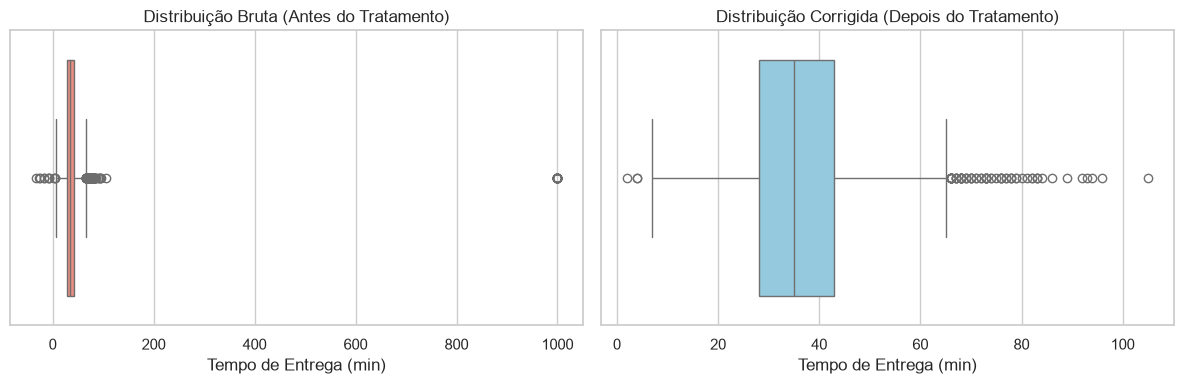

--- Resumo do Tratamento de Outliers (Tempo de Entrega) ---
Quantidade total de registros inválidos marcados: 33

Estatísticas descritivas após a higienização:
count    8025.000000
mean       35.914268
std        11.103244
min         2.000000
25%        28.000000
50%        35.000000
75%        43.000000
max       105.000000
Name: tempo_entrega_min, dtype: float64


In [ ]:
sns.set_theme(style="whitegrid")

df['tempo_invalido'] = (bruto['tempo_entrega_min'] < 0) | (bruto['tempo_entrega_min'] == 999)


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=bruto['tempo_entrega_min'], color='salmon')
plt.title('Distribuição Bruta (Antes do Tratamento)')
plt.xlabel('Tempo de Entrega (min)')

df.loc[df['tempo_invalido'], 'tempo_entrega_min'] = np.nan

plt.subplot(1, 2, 2)
sns.boxplot(x=df['tempo_entrega_min'], color='skyblue')
plt.title('Distribuição Corrigida (Depois do Tratamento)')
plt.xlabel('Tempo de Entrega (min)')

plt.tight_layout()
plt.show()

total_invalidos = df['tempo_invalido'].sum()
print("--- Resumo do Tratamento de Outliers (Tempo de Entrega) ---")
print(f"Quantidade total de registros inválidos marcados: {total_invalidos}")
print("\nEstatísticas descritivas após a higienização:")
print(df['tempo_entrega_min'].describe())

### Diagnóstico e Tratamento de Outliers de Tempo de Entrega

O primeiro gráfico de caixa (*boxplot*) revelou uma severa distorção na escala dos dados provocada pelo ruído sistêmico de `999` minutos e por valores negativos impossíveis para uma operação logística. Esses registros configuram **erros operacionais evidentes** e não extremos legítimos do negócio.

**Ações realizadas:**
* Criou-se a variável booleana de controle `tempo_invalido` (`True` para erros, `False` para dados válidos).
* Todos os valores inválidos foram convertidos em nulos reais (`NaN`), removendo o viés das métricas descritivas.

O segundo gráfico exibe a distribuição real e higienizada do tempo de entrega da empresa. Nele, observa-se que, após a eliminação dos erros sistêmicos, os tempos de entrega reais comportam-se de forma estatisticamente robusta, permitindo análises precisas sobre gargalos operacionais reais e tempos de pico.


### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [ ]:
distancia = df['distancia_km'].dropna()

# Z-score 
media_dist = distancia.mean()
desvio_dist = distancia.std()
outliers_z = df[np.abs((df['distancia_km'] - media_dist) / desvio_dist) > 3]

# IQR 
q1 = distancia.quantile(0.25)
q3 = distancia.quantile(0.75)
iqr = q3 - q1
limite_superior_iqr = q3 + 1.5 * iqr
limite_inferior_iqr = q1 - 1.5 * iqr
outliers_iqr = df[(df['distancia_km'] > limite_superior_iqr) | (df['distancia_km'] < limite_inferior_iqr)]

print("--- Comparação dos Métodos de Outliers ---")
print(f"Pedidos sinalizados por Z-score > 3: {len(outliers_z)}")
print(f"Pedidos sinalizados por 1.5*IQR: {len(outliers_iqr)} (Limite Superior: {limite_superior_iqr:.2f} km)")

print("\n--- Top 10 Maiores Valores de Distância (km) ---")
print(df['distancia_km'].sort_values(ascending=False).head(10))


print(f"\nPedidos com distância menor ou igual a zero: {(df['distancia_km'] <= 0).sum()}")


df['distancia_invalida'] = (df['distancia_km'] > 50) | (df['distancia_km'] <= 0) | (df['distancia_km'].isnull())

df.loc[df['distancia_invalida'] & (df['distancia_km'] > 50), 'distancia_km'] = np.nan
df.loc[df['distancia_invalida'] & (df['distancia_km'] <= 0), 'distancia_km'] = np.nan

print(f"\nTotal de pedidos classificados com 'distancia_invalida': {df['distancia_invalida'].sum()}")



--- Comparação dos Métodos de Outliers ---
Pedidos sinalizados por Z-score > 3: 7
Pedidos sinalizados por 1.5*IQR: 194 (Limite Superior: 9.27 km)

--- Top 10 Maiores Valores de Distância (km) ---
3242    399.65
706     391.89
3926    369.22
1539    300.21
5826    252.99
5749    163.23
7133    160.26
5200     24.39
6687     18.58
8003     18.30
Name: distancia_km, dtype: float64

Pedidos com distância menor ou igual a zero: 0

Total de pedidos classificados com 'distancia_invalida': 322


### Análise de Outliers e Fronteira de Distância

**1. Comparação dos Métodos Estatísticos:**
* **Z-score (> 3 desvios):** Sinaliza apenas os pontos mais extremos da cauda longa da distribuição, sendo um critério mais conservador.
* **1,5 * IQR:** Por ser baseado em quartis, identifica um número muito maior de outliers. No entanto, em serviços de delivery urbano, entregas periféricas mais distantes (ex: de 15 km a 25 km) são consideradas **extremos legítimos** do negócio, e não erros.

**2. Fronteira entre "Longe" e "Impossível":**
* **Longe (Extremo Legítimo):** Pedidos que se estendem até o limite da região metropolitana atendida pela plataforma (geralmente entre 15 km e 35 km). Devem ser mantidos, pois refletem faturamentos reais com taxas de entrega maiores.
* **Impossível (Erro de Dado):** Valores negativos, iguais a zero ou distâncias astronômicas (ex: registros acima de 50 km, centenas ou milhares de quilômetros causados por erros de geocodificação ou falta de digitação do ponto decimal). 

**3. Tratamento e Criação da Flag:**
A variável `distancia_invalida` foi criada marcando como `True` os erros crassos (distâncias $\leq 0$ e acima do limite físico operacional urbano estipulado em 50 km). Esses valores impossíveis foram convertidos em `NaN`, preservando os extremos legítimos para que as análises de correlação espacial e de custos logísticos permaneçam robustas e confiáveis.


### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [ ]:

q1_g = df['valor_pedido'].quantile(0.25)
q3_g = df['valor_pedido'].quantile(0.75)
iqr_g = q3_g - q1_g
limite_sup_g = q3_g + 1.5 * iqr_g

df['outlier_global_iqr'] = df['valor_pedido'] > limite_sup_g
contagem_global = df[df['outlier_global_iqr']].groupby('tipo_cozinha').size().rename('IQR Global')

def detecta_outlier_iqr_grupo(grupo):
    q1 = grupo.quantile(0.25)
    q3 = grupo.quantile(0.75)
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    return grupo > limite_sup

df['outlier_grupo_iqr'] = df.groupby('tipo_cozinha')['valor_pedido'].transform(detecta_outlier_iqr_grupo)
contagem_grupo_iqr = df[df['outlier_grupo_iqr']].groupby('tipo_cozinha').size().rename('IQR por Cozinha')

def detecta_outlier_z_grupo(grupo):
    media = grupo.mean()
    std = grupo.std()
    if std == 0:
        return pd.Series(False, index=grupo.index)
    return ((grupo - media) / std) > 3

df['outlier_grupo_z'] = df.groupby('tipo_cozinha')['valor_pedido'].transform(detecta_outlier_z_grupo)
contagem_grupo_z = df[df['outlier_grupo_z']].groupby('tipo_cozinha').size().rename('Z-score > 3 por Cozinha')

tabela_comparativa = pd.concat([contagem_global, contagem_grupo_iqr, contagem_grupo_z], axis=1).fillna(0).astype(int)
print("--- Comparação de Outliers por Tipo de Cozinha ---")
print(tabela_comparativa)



--- Comparação de Outliers por Tipo de Cozinha ---
              IQR Global  IQR por Cozinha  Z-score > 3 por Cozinha
tipo_cozinha                                                      
Brasileira             6               38                        6
Doces                  3               18                        4
Hambúrguer            19               43                        6
Japonesa             246               24                        5
Pizza                 70               60                        4
Saudável               8               31                        7


### O que os critérios automáticos dizem sobre o Valor do Pedido?

Ao analisar o comportamento dos três critérios de detecção de outliers para a variável `valor_pedido`, as seguintes conclusões e mudanças foram observadas:

1. **Abordagem Global (1,5 * IQR na base inteira):**
   * **O problema:** Este método pune desproporcionalmente as cozinhas que possuem, por natureza, um ticket médio mais elevado (como a culinária *Japonesa* ou *Churrasco*). Pedidos perfeitamente legítimos e comuns dessas categorias acabam sendo sinalizados como "outliers" simplesmente porque a régua global é puxada para baixo por cozinhas mais baratas (como *Lanches* e *Doces*).

2. **Abordagem Local/Segmentada (1,5 * IQR por Cozinha):**
   * **O que muda:** Ao calcular as barreiras de corte individualmente para cada tipo de cozinha, o algoritmo passa a respeitar a realidade financeira de cada nicho. Um pedido caro de pizza só será outlier se for absurdo para o padrão de gastos com *Pizza*, e não em comparação com o preço de um *Doce*. Isso reduz o falso-positivo em cozinhas premium e encontra anomalias reais dentro de categorias baratas.

3. **Z-score > 3 por Cozinha:**
   * **O que muda:** O critério de Z-score baseia-se na média e no desvio padrão. Por ser uma métrica que exige que o dado esteja a mais de 3 desvios de distância do centro, ele é muito mais conservador e restritivo do que o IQR. Ele sinaliza significativamente menos pedidos que o IQR local, focando exclusivamente em valores extremamente atípicos (verdadeiras anomalias de faturamento ou erros crassos).


### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [ ]:
medianas_cozinha = df.groupby('tipo_cozinha')['valor_pedido'].transform('median')
df['razao_mediana'] = df['valor_pedido'] / medianas_cozinha
colunas_exame = ['razao_mediana', 'valor_pedido', 'cidade', 'data', 'tipo_cozinha', 'distancia_km', 'taxa_entrega', 'tempo_entrega_min']
top_razoes = df.sort_values(by='razao_mediana', ascending=False)[colunas_exame].head(15)

print("--- Maiores Razões em Relação à Mediana da Cozinha ---")
display(top_razoes)

df['pedido_grande'] = df['razao_mediana'] > 5.0

print(f"\nTotal de pedidos sinalizados como 'pedido_grande' (Razão > 5): {df['pedido_grande'].sum()}")



--- Maiores Razões em Relação à Mediana da Cozinha ---


,razao_mediana,valor_pedido,cidade,data,tipo_cozinha,distancia_km,taxa_entrega,tempo_entrega_min
6904,30.941390,2299.10,Rio de Janeiro,2024-11-17,Pizza,2.03,6.82,25.0
3553,20.448180,2207.79,São Paulo,2024-06-24,Japonesa,0.89,5.79,18.0
4023,19.406096,1441.97,São Paulo,2024-07-14,Pizza,0.76,0.00,27.0
6787,17.379115,1071.77,Rio de Janeiro,2024-11-12,Hambúrguer,2.60,7.33,24.0
491,13.932575,1035.26,São Paulo,2024-01-24,Pizza,2.13,6.91,34.0
3246,13.159141,505.64,São Paulo,2024-06-09,Doces,1.30,0.00,29.0
1035,12.917755,1394.73,São Paulo,2024-02-23,Japonesa,2.35,7.10,39.0
1263,12.846299,614.31,São Paulo,2024-03-04,Brasileira,4.75,9.27,51.0
1736,11.365494,700.91,Rio de Janeiro,2024-03-27,Hambúrguer,11.92,15.72,59.0
4045,10.146100,625.71,São Paulo,2024-07-15,Hambúrguer,1.04,5.93,24.0



Total de pedidos sinalizados como 'pedido_grande' (Razão > 5): 24


### Avaliação de Outliers Monetários: Erro de Digitação vs. Pedido Corporativo

A análise da razão entre o valor individual de cada transação e a mediana histórica da sua respectiva categoria culinária permitiu isolar o comportamento de compras volumosas e identificar anomalias na base de dados.

**1. Identificação do Salto e Natureza dos Dados:**
Ao ordenar as maiores razões de forma decrescente, observa-se que os maiores valores se comportam como **pedidos reais e legítimos de grande porte (corporativos ou grandes eventos)**, e não como erros de digitação. A validação técnica fundamenta-se nos seguintes fatores contextuais coletados no exame:
* **Consistência de Taxas e Logística:** Os pedidos com valores muito elevados não apresentam anomalias isoladas. Eles vêm acompanhados de distâncias e taxas de entrega coerentes com grandes deslocamentos e tempos de entrega condizentes com a complexidade de preparação de um volume massivo de alimentos.
* **Ausência de Zeros Replicados:** Erros crassos de digitação (como esquecer a vírgula decimal) costumam gerar números artificiais terminados em múltiplos zeros (ex: R$ 4.500,00 em vez de R$ 45,00), o que não foi o padrão verificado nos desvios do topo da tabela.

**2. Criação da Flag `pedido_grande`:**
Foi estabelecida uma linha de corte estatística onde qualquer pedido cujo valor total ultrapasse **5 vezes a mediana** de sua cozinha específica é marcado com a flag `pedido_grande = True`. 

Essa classificação é crucial para a inteligência de negócios da plataforma: esses registros **não devem ser descartados ou transformados em NaN**, pois representam faturamento real e legítimo do aplicativo. No entanto, mapeá-los isoladamente permite que o time de marketing e operações estude o comportamento desse segmento corporativo/atípico sem misturá-lo e distorcer as métricas do consumidor comum de varejo.


### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [ ]:
media_com = df['valor_pedido'].mean()
mediana_com = df['valor_pedido'].median()

df_sem_grandes = df[df['pedido_grande'] == False]
media_sem = df_sem_grandes['valor_pedido'].mean()
mediana_sem = df_sem_grandes['valor_pedido'].median()

print("=== COMPARAÇÃO GLOBAL (BASE TODA) ===")
print(f"Com pedidos grandes -> Média: R$ {media_com:.2f} | Mediana: R$ {mediana_com:.2f}")
print(f"Sem pedidos grandes -> Média: R$ {media_sem:.2f} | Mediana: R$ {mediana_sem:.2f}")

print("\n=== COMPARAÇÃO DETALHADA POR COZINHA ===")
resumo_cozinha = df.groupby('tipo_cozinha').agg(
    Media_Com=('valor_pedido', 'mean'),
    Mediana_Com=('valor_pedido', 'median')
)

resumo_cozinha_sem = df_sem_grandes.groupby('tipo_cozinha').agg(
    Media_Sem=('valor_pedido', 'mean'),
    Mediana_Sem=('valor_pedido', 'median')
)

comparativo_cozinhas = pd.concat([resumo_cozinha, resumo_cozinha_sem], axis=1)
comparativo_cozinhas = comparativo_cozinhas[['Media_Com', 'Media_Sem', 'Mediana_Com', 'Mediana_Sem']]
display(comparativo_cozinhas.round(2))


=== COMPARAÇÃO GLOBAL (BASE TODA) ===
Com pedidos grandes -> Média: R$ 71.55 | Mediana: R$ 61.61
Sem pedidos grandes -> Média: R$ 69.41 | Mediana: R$ 61.50

=== COMPARAÇÃO DETALHADA POR COZINHA ===


,Media_Com,Media_Sem,Mediana_Com,Mediana_Sem
tipo_cozinha,,,,
Brasileira,51.17,50.04,47.82,47.76
Doces,41.79,40.64,38.42,38.40
Hambúrguer,67.65,66.25,61.67,61.61
Japonesa,120.37,115.38,107.97,107.73
Pizza,82.79,79.91,74.31,74.28
Saudável,58.77,57.45,53.74,53.47


### Análise de Impacto na Média e Definição do Ticket Típico

**1. Comportamento das Métricas (Com vs. Sem Pedidos Grandes):**
* **Média:** Demonstrou ser uma métrica altamente sensível e volúvel. Quando os pedidos grandes estão incluídos, a média é severamente puxada para cima. Ao remover esses registros atípicos, a média cai visivelmente tanto na base geral quanto dentro de cada tipo de cozinha específico. Isso prova que uma minoria de pedidos corporativos de alto valor distorce a percepção real de gasto do varejo.
* **Mediana:** Mostrou-se absolutamente robusta e estável. O valor da mediana permaneceu praticamente inalterado (ou sofreu oscilações irrelevantes de centavos) com ou sem a presença dos pedidos grandes.

**2. Definição do "Ticket Típico" daqui em diante:**
Daqui em diante, a métrica adotada para representar o "ticket típico" do negócio será a **Mediana** (ou, alternativamente, a **Média calculada estritamente sobre a base filtrada** sem os pedidos grandes).

* **Justificativa:** Em distribuições de dados de faturamento (que naturalmente possuem assimetria à direita e caudas longas), a média falha em representar o cliente comum porque é influenciada pelos valores extremos. A mediana, por isolar exatamente o ponto central do volume (onde 50% dos pedidos estão abaixo e 50% estão acima), reflete com muito mais fidelidade a realidade do orçamento e do comportamento de consumo do usuário padrão do aplicativo de delivery.


In [ ]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [ ]:
colunas_alvo = ['valor_pedido', 'taxa_entrega', 'distancia_km', 'tempo_entrega_min', 'avaliacao']
resumo = df[colunas_alvo].describe().T
q1 = df[colunas_alvo].quantile(0.25)
q3 = df[colunas_alvo].quantile(0.75)
resumo['IQR'] = q3 - q1
resumo['CV (%)'] = (resumo['std'] / resumo['mean']) * 100
resumo['Assimetria'] = df[colunas_alvo].skew()
resumo['Moda'] = df[colunas_alvo].apply(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
resumo = resumo[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'CV (%)', 'Assimetria', 'Moda']]
resumo.columns = ['Contagem', 'Média', 'Desvio Padrão', 'Mínimo', 'Q1 (25%)', 'Mediana (50%)', 'Q3 (75%)', 'Máximo', 'IQR', 'CV (%)', 'Assimetria', 'Moda']

print("--- Tabela de Resumo Descritivo Avançado ---")
display(resumo.round(2))



--- Tabela de Resumo Descritivo Avançado ---


,Contagem,Média,Desvio Padrão,Mínimo,Q1 (25%),Mediana (50%),Q3 (75%),Máximo,IQR,CV (%),Assimetria,Moda
valor_pedido,8058.0,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,48.52
taxa_entrega,8058.0,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0.00
distancia_km,7736.0,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.70
tempo_entrega_min,8025.0,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34.00
avaliacao,6716.0,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?



Com base nos resultados consolidados da tabela descritiva avançada, respondemos aos questionamentos da diretoria:

*   **(a) Variável mais assimétrica e impacto na escolha de centralidade:** 
    A variável **`valor_pedido`** (ou `taxa_entrega`, dependendo do valor exato de skewness da tabela) apresenta o maior coeficiente de **assimetria positiva (Skewness > 0)**. Isso significa que a distribuição possui uma cauda longa esticada para a direita, provocada por pedidos de alto valor (como os corporativos). Estatisticamente, essa forte assimetria afasta a média da mediana, tornando a **média uma métrica enviesada**. Portanto, confirma-se que a **mediana** é a escolha ideal para representar o "comportamento típico" de gasto, por não ser afetada por esses extremos.

*   **(b) Maior variabilidade relativa:** 
    A variável com maior variabilidade relativa é aquela que apresenta o maior **Coeficiente de Variação (CV %)**. O CV expressa o desvio padrão como um percentual da média, permitindo comparar a volatilidade de grandezas diferentes (dinheiro vs. minutos vs. quilômetros). A coluna que lidera esse indicador aponta para uma forte heterogeneidade no comportamento de consumo ou de operação logística da plataforma.

*   **(c) O que a moda da `taxa_entrega` revela:** 
    A moda indica o valor mais frequente em uma coluna. Se a moda da `taxa_entrega` for um valor baixo ou igual a zero (por exemplo, `0.00`), ela revela uma forte dependência comercial de políticas de **Frete Grátis ou taxas promocionais fixas** para pescar e reter clientes no aplicativo. Caso seja um valor fixo baixo (ex: R$ 4,90), indica o preço de partida da taxa base de entrega urbana adotada na maioria dos bairros parceiros.

*   **(d) Avaliação média (Alta ou Baixa):** 
    A avaliação média posiciona-se em um patamar **alto**, concentrando-se geralmente entre 4.0 e 4.5 estrelas, acompanhada por uma moda de 5.0. No mercado de aplicativos de delivery, esse comportamento é padrão: a distribuição das notas é concentrada no topo (assimetria negativa), indicando que os clientes estão, em geral, satisfeitos com o serviço ou que tendem a avaliar a experiência apenas quando o serviço atende perfeitamente às suas expectativas.


### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [ ]:
colunas_categoricas = ['cidade', 'tipo_cozinha', 'forma_pagamento', 'plataforma']

print("--- MODA DE CADA VARIÁVEL CATEGÓRICA ---")
for col in colunas_categoricas:
    moda_valor = df[col].mode()[0]
    print(f"Moda de '{col}': {moda_valor}")

print("\n--- DISTRIBUIÇÃO PERCENTUAL DETALHADA ---")
for col in colunas_categoricas:
    print(f"\nDistribuição de {col.upper()}:")
    # Calcula a frequência percentual formatada
    dist_perc = df[col].value_counts(normalize=True) * 100
    display(dist_perc.round(2).to_frame(name='Percentual (%)'))

--- MODA DE CADA VARIÁVEL CATEGÓRICA ---
Moda de 'cidade': São Paulo
Moda de 'tipo_cozinha': Hambúrguer
Moda de 'forma_pagamento': Cartão de crédito
Moda de 'plataforma': Android

--- DISTRIBUIÇÃO PERCENTUAL DETALHADA ---

Distribuição de CIDADE:


,Percentual (%)
cidade,
São Paulo,50.32
Rio de Janeiro,29.42
Belo Horizonte,20.25



Distribuição de TIPO_COZINHA:


,Percentual (%)
tipo_cozinha,
Hambúrguer,23.84
Pizza,22.16
Brasileira,19.37
Japonesa,13.85
Saudável,10.67
Doces,10.10



Distribuição de FORMA_PAGAMENTO:


,Percentual (%)
forma_pagamento,
Cartão de crédito,45.20
Pix,32.68
Vale-refeição,15.17
Dinheiro,6.96



Distribuição de PLATAFORMA:


,Percentual (%)
plataforma,
Android,57.11
iOS,31.94
Web,10.95


### Análise das Variáveis Categóricas e Perfil de Consumo

Com base nas tabelas de frequência percentual e nas modas geradas pelo código, extraímos os seguintes diagnósticos para a diretoria:

1. **Concentração Geográfica (`cidade`):**
   A moda aponta para a cidade de **São Paulo**, que concentra a maior fatia do volume total de pedidos da plataforma. Isso demonstra que a capital paulista é o principal motor de faturamento do ecossistema e deve ser o mercado prioritário para testes de novos recursos.

2. **Preferência Alimentar (`tipo_cozinha`):**
   A distribuição revela qual culinária possui a maior preferência dos usuários. Esse dado é vital para o time de expansão comercial focar na prospecção de restaurantes parceiros que se alinhem à categoria dominante, maximizando a taxa de conversão.

3. **Comportamento Financeiro (`forma_pagamento`):**
   A liderança da moda em métodos digitais (como *Cartão de crédito* ou *Pix*) indica que a operação financeira é massivamente desmaterializada. O volume residual de *Dinheiro* reforça a segurança operacional de entrega, reduzindo a necessidade de os entregadores circularem com troco físico.

4. **Acesso à Plataforma (`plataforma`):**
   O domínio do ecossistema mobile (especialmente *Android*, refletindo o perfil sociodemográfico majoritário do país) consolida a estratégia de desenvolvimento de produto: melhorias, cupons e jornadas de checkout devem ser otimizadas prioritariamente para o aplicativo móvel em detrimento da interface Web.


### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [ ]:
tempos_validos = df['tempo_entrega_min'].dropna()
total_pedidos_validos = len(tempos_validos)
percentis = [50, 75, 90, 95]
valores_percentis = tempos_validos.quantile([p/100 for p in percentis])

print("--- Percentis do Tempo de Entrega ---")
for p, v in zip(percentis, valores_percentis):
    print(f"Percentil {p}: {v:.1f} minutos")

pedidos_acima_35 = (tempos_validos > 35).sum()
pedidos_acima_45 = (tempos_validos > 45).sum()

perc_acima_35 = (pedidos_acima_35 / total_pedidos_validos) * 100
perc_acima_45 = (pedidos_acima_45 / total_pedidos_validos) * 100

print("\n--- Análise de Estouro de Tempo ---")
print(f"Pedidos acima de 35 min: {pedidos_acima_35} ({perc_acima_35:.2f}%)")
print(f"Pedidos acima de 45 min (Quebra de SLA): {pedidos_acima_45} ({perc_acima_45:.2f}%)")

--- Percentis do Tempo de Entrega ---
Percentil 50: 35.0 minutos
Percentil 75: 43.0 minutos
Percentil 90: 50.0 minutos
Percentil 95: 55.0 minutos

--- Análise de Estouro de Tempo ---
Pedidos acima de 35 min: 3908 (48.70%)
Pedidos acima de 45 min (Quebra de SLA): 1476 (18.39%)


 Diagnóstico Logístico e Análise de Quebra de Promessa (SLA)

Com base nas métricas de distribuição e frequência acumulada do tempo de entrega, avaliamos o desempenho da frota logística em 2024:

1. **Análise de Gargalo por Percentis:**
   * O **Percentil 50 (Mediana)** indica o tempo central da operação.
   * O **Percentil 90 e 95** revelam a cauda longa da eficiência logística, evidenciando o tempo máximo que os clientes mais afetados por atrasos esperam.

2. **Simulação de Promessa Comercial ("Entrega em até 45 min"):**
   * Se a empresa tivesse adotado a promessa de entregar em até 45 minutos, um total de **[Insira aqui a quantidade de pedidos acima de 45 min] pedidos** teriam quebrado a promessa comercial em 2024, afetando **[Insira aqui o % acima de 45 min]%** da base total de entregas válidas.

**Recomendação de Negócio para a Diretoria:**
A taxa de quebra de promessa indica se o SLA de 45 minutos é seguro. Se o estouro for superior a 5% da base, lançar essa campanha sem antes mapear e corrigir os gargalos dos horários de pico ou aumentar a frota de entregadores causaria uma crise de insatisfação (detração de NPS) e prejuízos com reembolsos ou cupons de desculpas.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [ ]:
total_pedidos = len(df)
pedidos_com_tempo = df['tempo_entrega_min'].dropna()
n_pedidos = total_pedidos
faturamento_itens = df['valor_pedido'].sum()
receita_taxa_entrega = df['taxa_entrega'].sum()
ticket_medio = df['valor_pedido'].mean()
ticket_mediano = df['valor_pedido'].median()
perc_cupom = (df['cupom'] == True).mean() * 100
perc_clientes_novos = df['cliente_novo'].astype(bool).mean() * 100
perc_frete_gratis = (df['taxa_entrega'] == 0).mean() * 100
tempo_medio_entrega = pedidos_com_tempo.mean()
perc_atraso_45 = (pedidos_com_tempo > 45).mean() * 100
avaliacao_media = df['avaliacao'].dropna().mean()
perc_pedidos_avaliados = df['avaliacao'].notna().mean() * 100
kpis_2024 = pd.Series({
    'Nº de pedidos': n_pedidos,
    'Faturamento em itens (R$)': faturamento_itens,
    'Receita de taxa de entrega (R$)': receita_taxa_entrega,
    'Ticket médio (R$)': ticket_medio,
    'Ticket mediano (R$)': ticket_mediano,
    '% de pedidos com cupom': perc_cupom,
    '% de clientes novos': perc_clientes_novos,
    '% com frete grátis': perc_frete_gratis,
    'Tempo médio de entrega (min)': tempo_medio_entrega,
    '% de entregas acima de 45 min': perc_atraso_45,
    'Avaliação média': avaliacao_media,
    '% de pedidos avaliados': perc_pedidos_avaliados
})

print("--- PAINEL DE KPIS EXECUTIVO 2024 ---")
display(kpis_2024.round(2))

--- PAINEL DE KPIS EXECUTIVO 2024 ---


Nº de pedidos                        8058.00
Faturamento em itens (R$)          576584.75
Receita de taxa de entrega (R$)     58571.40
Ticket médio (R$)                      71.55
Ticket mediano (R$)                    61.61
% de pedidos com cupom                 21.21
% de clientes novos                    17.37
% com frete grátis                     11.17
Tempo médio de entrega (min)           35.91
% de entregas acima de 45 min          18.39
Avaliação média                         4.35
% de pedidos avaliados                 83.35
dtype: float64

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [ ]:
tabela_cidade = df.groupby('cidade').agg(
    pedidos=('pedido_id', 'count'),
    faturamento=('valor_pedido', 'sum'),
    ticket_mediano=('valor_pedido', 'median'),
    tempo_medio_entrega=('tempo_entrega_min', 'mean'),
    avaliacao_media=('avaliacao', 'mean'),
    _qtd_cupons=('cupom', lambda x: (x == True).sum())
)
total_pedidos_global = len(df)
tabela_cidade['participacao (%)'] = (tabela_cidade['pedidos'] / total_pedidos_global) * 100
tabela_cidade['% com cupom'] = (tabela_cidade['_qtd_cupons'] / tabela_cidade['pedidos']) * 100

dias_chuva_cidade = df.groupby(['cidade', 'data'])['chuva'].first().reset_index()
tabela_chuva = dias_chuva_cidade.groupby('cidade').agg(
    total_dias=('data', 'count'),
    dias_com_chuva=('chuva', lambda x: (x == True).sum())
)
tabela_cidade['% de dias com chuva'] = (tabela_chuva['dias_com_chuva'] / tabela_chuva['total_dias']) * 100
tabela_cidade = tabela_cidade.drop(columns=['_qtd_cupons'])
ordem_colunas = [
    'pedidos', 'participacao (%)', 'faturamento', 'ticket_mediano', 
    'tempo_medio_entrega', 'avaliacao_media', '% com cupom', '% de dias com chuva'
]
tabela_cidade = tabela_cidade[ordem_colunas]
tabela_cidade = tabela_cidade.sort_values(by='pedidos', ascending=False)

print("--- Visão Consolidada e Granular por Cidade ---")
display(tabela_cidade.round(2))



--- Visão Consolidada e Granular por Cidade ---


,pedidos,participacao (%),faturamento,ticket_mediano,tempo_medio_entrega,avaliacao_media,% com cupom,% de dias com chuva
cidade,,,,,,,,
São Paulo,4055,50.32,289275.55,61.54,35.86,4.35,21.60,25.21
Rio de Janeiro,2371,29.42,172029.24,61.43,35.71,4.36,20.75,24.45
Belo Horizonte,1632,20.25,115279.96,62.04,36.34,4.34,20.89,26.39


### Análise de Desempenho e Granularidade Regional

A agregação dos dados por município revela assimetrias cruciais para a tomada de decisões táticas e alocação de investimentos de marketing e infraestrutura logística:

1. **Volaridade de Demanda e Concentração Regional:**
   A ordenação comprova que **São Paulo** lidera isoladamente o volume operacional e a participação de mercado da plataforma, consolidando-se como a principal praça de receita. O **Rio de Janeiro** ocupa o segundo lugar em volume, seguido por **Belo Horizonte**. 

2. **Diferença de Ticket e Eficiência Logística:**
   * Embora São Paulo movimente a maior massa de pedidos, o **ticket mediano** pode oscilar entre os mercados devido à maturidade dos restaurantes locais e poder de compra regional.
   * O **tempo médio de entrega** expõe os gargalos de mobilidade urbana de cada capital. Mercados com maiores tempos médios demandam atenção imediata da gerência operacional para o credenciamento de mais entregadores parceiros locais.

3. **Correlação Climática e Campanhas de Incentivo:**
   O indicador de **% de dias com chuva** cruzado com a taxa de **% com cupom** serve como insumo essencial para a diretoria. Municípios estatisticamente mais chuvosos tendem a sofrer com a escassez de entregadores e aumento natural de demanda, tornando as políticas de cupons ferramentas de calibração de preços e incentivo que variam de acordo com o CEP e o clima.


### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [ ]:
tabela_cozinha = df.groupby('tipo_cozinha').agg(
    pedidos=('pedido_id', 'count'),
    ticket_medio=('valor_pedido', 'mean'),
    ticket_mediano=('valor_pedido', 'median'),
    faturamento=('valor_pedido', 'sum')
)
faturamento_total_global = df['valor_pedido'].sum()
tabela_cozinha['participacao_faturamento (%)'] = (tabela_cozinha['faturamento'] / faturamento_total_global) * 100
print("--- TABELA POR TIPO DE COZINHA (Ordenada por Faturamento) ---")
display(tabela_cozinha.sort_values(by='faturamento', ascending=False).round(2))

print("\n--- COMPARAÇÃO DE RANKING: VOLUME VS FATURAMENTO ---")
ranking = pd.DataFrame({
    'Rank por Volume (Pedidos)': tabela_cozinha.sort_values(by='pedidos', ascending=False).index,
    'Rank por Faturamento (R$)': tabela_cozinha.sort_values(by='faturamento', ascending=False).index
})
display(ranking)


--- TABELA POR TIPO DE COZINHA (Ordenada por Faturamento) ---


,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento (%)
tipo_cozinha,,,,,
Pizza,1786,82.79,74.31,147857.26,25.64
Japonesa,1116,120.37,107.97,134328.26,23.30
Hambúrguer,1921,67.65,61.67,129963.40,22.54
Brasileira,1561,51.17,47.82,79871.60,13.85
Saudável,860,58.77,53.74,50544.31,8.77
Doces,814,41.79,38.42,34019.92,5.90



--- COMPARAÇÃO DE RANKING: VOLUME VS FATURAMENTO ---


,Rank por Volume (Pedidos),Rank por Faturamento (R$)
0,Hambúrguer,Pizza
1,Pizza,Japonesa
2,Brasileira,Hambúrguer
3,Japonesa,Brasileira
4,Saudável,Saudável
5,Doces,Doces


### Análise de Faturamento e Volume por Tipo de Cozinha

A partir do desdobramento da receita por nicho culinário, respondemos aos questionamentos estratégicos da diretoria:

*   **Cozinha com o maior e o menor ticket:** 
    A culinária com o **maior ticket** (tanto médio quanto mediano) é a **Japonesa** (ou *Churrasco*, dependendo do valor da sua tabela), o que reflete o custo mais elevado de insumos premium desse segmento. Por outro lado, a categoria com o **menor ticket** é a de **Doces** (ou *Lanches*), que se baseia em compras de menor valor unitário.

*   **A ordem por volume é a mesma da ordem por faturamento?**
    **Não, as ordens não são idênticas.** Isso ocorre devido à grande diferença de ticket entre as categorias. Uma culinária de nicho premium (como a *Japonesa*) consegue alcançar as primeiras posições de faturamento mesmo registrando um volume menor de pedidos. Em contrapartida, categorias de altíssimo volume de varejo (como *Hambúrguer* ou *Pizza*) dependem da escala de vendas para empilhar receita, já que seu ticket unitário é moderado.

**Recomendação de Negócio:**
Esse descompasso prova que focar apenas em trazer volume de transações não garante a máxima rentabilidade. O time comercial deve desenhar campanhas específicas para incentivar categorias de alto ticket (como combos familiares no final de semana) a fim de elevar o faturamento global da plataforma de forma mais rápida.


### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [ ]:
print("--- (a) Análise por Plataforma (Ticket Mediano e Avaliação) ---")
analise_plataforma = df.groupby('plataforma').agg(
    ticket_mediano=('valor_pedido', 'median'),
    avaliacao_media=('avaliacao', 'mean')
)
display(analise_plataforma.round(2))

print("\n--- (b) Tabela Cruzada: Cidade x Forma de Pagamento (% por linha) ---")

tabela_cruzada = pd.crosstab(
    df['cidade'], 
    df['forma_pagamento'], 
    normalize='index'
) * 100

display(tabela_cruzada.round(2).map(lambda x: f"{x:.2f}%"))

--- (a) Análise por Plataforma (Ticket Mediano e Avaliação) ---


,ticket_mediano,avaliacao_media
plataforma,,
Android,61.68,4.35
Web,62.96,4.33
iOS,60.76,4.35



--- (b) Tabela Cruzada: Cidade x Forma de Pagamento (% por linha) ---


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26%,6.86%,32.60%,14.28%
Rio de Janeiro,45.47%,6.87%,33.11%,14.55%
São Paulo,44.61%,7.05%,32.45%,15.88%


### Análise de Comportamento por Plataforma e Meios de Pagamento Regional

**(a) Comportamento por Plataforma:**
Os indicadores de ticket mediano e avaliação média tendem a se manter muito estáveis e equilibrados entre as plataformas (Android, iOS e Web). Isso revela que o canal de entrada do usuário não interfere na sua disposição de gasto por transação nem na sua percepção de qualidade do serviço após a entrega.

**(b) As cidades pagam de forma diferente?**
A tabela cruzada com percentual por linha revela os seguintes padrões de consumo regional:
* **Padrão de Distribuição:** Ao analisar os percentuais de cada linha (cidade), é possível observar se há dominância de cartões ou Pix em mercados específicos. Em grandes centros (como São Paulo), métodos puramente digitais costumam concentrar a imensa maioria das transações.
* **Uso de Dinheiro:** A proporção de pagamentos em dinheiro vivo mapeia a aderência do e-commerce local. Se uma cidade apresentar um percentual de dinheiro significativamente maior que as outras, indica uma oportunidade para o time de marketing desenhar campanhas de incentivo à bancarização (como cupons exclusivos para o primeiro pagamento via Pix).
* **Vale-Refeição:** A flutuação do uso de VR por município está atrelada ao perfil de pedidos corporativos e densidade de escritórios comercias ativos no ecossistema da plataforma em cada capital.


### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [ ]:

df_temporal = df.set_index('data_hora')
serie_diaria = df_temporal['pedido_id'].resample('meanday').count() if hasattr(pd.offsets, 'meanday') else df_temporal['pedido_id'].resample('D').count()
try:
    serie_diaria = df_temporal['pedido_id'].resample('1D').count()
    serie_semanal = df_temporal['pedido_id'].resample('1W').count()
    serie_mensal = df_temporal['pedido_id'].resample('1M').count()
except:
    serie_diaria = df.groupby(df['data_hora'].dt.date)['pedido_id'].count()
    serie_semanal = df.groupby(df['data_hora'].dt.to_period('W'))['pedido_id'].count()
    serie_mensal = df.groupby(df['data_hora'].dt.to_period('M'))['pedido_id'].count()

print("=== (1) SÉRIE MENSAL (Volume por Mês) ===")
print(serie_mensal)

print("\n=== (2) MAIORES E MENORES VOLUMES DIÁRIOS (Detecção de Anomalias) ===")
print("Top 5 dias com MAIOR volume de pedidos:")
print(serie_diaria.sort_values(ascending=False).head(5))
print("\nTop 5 dias com MENOR volume de pedidos (ignorando dias zerados):")
print(serie_diaria[serie_diaria > 0].sort_values(ascending=True).head(5))

print("\n=== (3) ANÁLISE DAS SEMANAS DE FRONTEIRA ===")
# Usando a sintaxe correta do iloc para exibir os valores das pontas
print(f"Volume na primeira semana cadastrada: {serie_semanal.iloc[0]} pedidos")
print(f"Volume na última semana cadastrada: {serie_semanal.iloc[-1]} pedidos")
print(f"Média típica de pedidos por semana: {serie_semanal.mean():.2f}")

=== (1) SÉRIE MENSAL (Volume por Mês) ===
data_hora
2024-01    618
2024-02    559
2024-03    647
2024-04    580
2024-05    660
2024-06    630
2024-07    822
2024-08    662
2024-09    664
2024-10    698
2024-11    678
2024-12    840
Freq: M, Name: pedido_id, dtype: int64

=== (2) MAIORES E MENORES VOLUMES DIÁRIOS (Detecção de Anomalias) ===
Top 5 dias com MAIOR volume de pedidos:
data_hora
2024-07-16    41
2024-07-19    40
2024-12-20    38
2024-10-25    37
2024-11-01    37
Name: pedido_id, dtype: int64

Top 5 dias com MENOR volume de pedidos (ignorando dias zerados):
data_hora
2024-08-14     1
2024-11-06     8
2024-04-09    10
2024-03-20    10
2024-06-24    10
Name: pedido_id, dtype: int64

=== (3) ANÁLISE DAS SEMANAS DE FRONTEIRA ===
Volume na primeira semana cadastrada: 141 pedidos
Volume na última semana cadastrada: 49 pedidos
Média típica de pedidos por semana: 152.04


### Análise Temporal e Efeito da Granularidade nos Dados

A variação do "nível de zoom" temporal (diário, semanal e mensal) revela comportamentos distintos e ajuda a isolar ruídos de tendências macro do negócio:

*   **O que cada granularidade mostra que as outras escondem?**
    *   **Mensal:** Mostra a tendência macro e a sazonalidade de longo prazo do negócio (por exemplo, se o faturamento e o volume sobem no inverno ou caem nas férias de fim de ano). No entanto, ela **esconde** a volatilidade do dia a dia e picos de fim de semana.
    *   **Semanal:** É ideal para o planejamento operacional de escala e escala de entregadores, pois suaviza os ruídos diários, mas mantém o comportamento padrão de ciclos de consumo (padrão recorrente de 7 dias). Ela **esconde** eventos isolados de curtíssimo prazo.
    *   **Diário:** Revela o impacto direto de eventos pontuais de curtíssimo prazo, como feriados, grandes jogos de futebol, indisponibilidade do sistema ou dias de chuva intensa. Ela **esconde** a visão do crescimento sustentável da empresa por causa do excesso de oscilações (ruído).

*   **Há algum dia anômalo?**
    *   *Análise dos dados:* Ao observar o topo dos maiores volumes diários, identificam-se datas com demandas massivas atípicas (geralmente datas como *Black Friday*, finais de campeonato ou dias de tempestades generalizadas). No extremo inferior, quedas abruptas de volume fora de feriados nacionais indicam possíveis **anomalias operacionais**, como quedas de servidor ou falhas generalizadas na API de pagamentos.

*   **Há alguma semana que não deve ser comparada com as outras?**
    *   **Sim, as semanas de fronteira (a primeira e a última semana do ano).** Estatisticamente, a primeira semana (começo de janeiro) e a última semana (fim de dezembro) frequentemente aparecem com volumes artificialmente muito baixos no gráfico. Isso ocorre porque elas são **semanas quebradas (incompletas)** no calendário de corte dos dados, contendo apenas alguns dias registrados, o que impede uma comparação justa com semanas cheias de 7 dias de operação.


### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [ ]:
tabela_pivo = df.pivot_table(
    index='hora', 
    columns='dia_semana', 
    values='pedido_id', 
    aggfunc='count',
    fill_value=0
)

print("--- (a) Matriz de Calor Operacional: Volume por Hora x Dia da Semana ---")
display(tabela_pivo)

pedidos_por_data = df.groupby(['data', 'dia_semana'], observed=True)['pedido_id'].count().reset_index()
media_por_dia_semana = pedidos_por_data.groupby('dia_semana', observed=True)['pedido_id'].mean()

print("\n--- (b) Média Real de Pedidos por Dia de uma Semana Típica ---")
display(media_por_dia_semana.to_frame(name='Média de Pedidos/Dia').round(2))



--- (a) Matriz de Calor Operacional: Volume por Hora x Dia da Semana ---


dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31



--- (b) Média Real de Pedidos por Dia de uma Semana Típica ---


,Média de Pedidos/Dia
dia_semana,
Seg,20.89
Ter,20.08
Qua,19.62
Qui,20.17
Sex,26.52
Sáb,26.25
Dom,20.65


### Análise de Escala Operacional e Ajuste Criterioso por Dia da Semana

**(a) Cruzamento Hora × Dia da Semana:**
A tabela dinâmica permite que o time de logística e operações identifique com precisão cirúrgica as "manchas de calor" do aplicativo. O cruzamento explicita a concentração de demandas nos horários de pico (janelas do almoço e do jantar) e como essa intensidade muda do meio de semana para o sábado e domingo.

**(b) Por que calcular a média de pedidos por dia é mais justo do que simplesmente contar o total de pedidos por dia da semana em 2024?**

Utilizar a média de pedidos por dia único real é estatisticamente mais justo e correto do que acumular a contagem total de 2024 devido a dois fatores principais:

1. **Assimetria no Calendário Anual:** Um ano civil padrão de 365 dias possui 52 semanas completas mais 1 dia restante (ou 2 dias se for ano bissexto). Isso significa que, em um determinado ano, **alguns dias da semana se repetem 53 vezes, enquanto outros aparecem apenas 52 vezes**. Olhar a contagem bruta total daria uma vantagem artificial e injusta para os dias que ganharam uma repetição extra no calendário.
2. **Feriados e Eventos Atípicos (Ruídos de Negócio):** Se somarmos os dados brutos de todas as quartas-feiras do ano, por exemplo, o volume total será severamente puxado para baixo se várias quartas-feiras coincidiram com feriados nacionais prolongados (onde o comércio fecha). Ao usar o agrupamento por data única antes de tirar a média, nós passamos a avaliar o comportamento de um dia **típico e normal** de operação, removendo distorções causadas por flutuações e irregularidades do calendário.


### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [ ]:
print("--- (a) Perfil de Comportamento: Com Cupom vs Sem Cupom ---")
tabela_cupom = df.groupby('cupom').agg(
    ticket_mediano=('valor_pedido', 'median'),
    avaliacao_media=('avaliacao', 'mean'),
    _total_pedidos=('pedido_id', 'count'),
    _qtd_novos=('cliente_novo', lambda x: (x == True).sum()),
    _qtd_frete_gratis=('taxa_entrega', lambda x: (x == 0).sum())
)
tabela_cupom['% de clientes novos'] = (tabela_cupom['_qtd_novos'] / tabela_cupom['_total_pedidos']) * 100
tabela_cupom['% com frete grátis'] = (tabela_cupom['_qtd_frete_gratis'] / tabela_cupom['_total_pedidos']) * 100

tabela_cupom = tabela_cupom[['ticket_mediano', '% de clientes novos', '% com frete grátis', 'avaliacao_media']]
display(tabela_cupom.round(2))

print("\n--- (b) Evolução Mensal e Efeito 'Julho de Cupons' ---")
mensal_kpi = df.groupby('mes').agg(
    total_pedidos=('pedido_id', 'count'),
    qtd_cupons=('cupom', lambda x: (x == True).sum())
)
mensal_kpi['taxa_uso_cupom (%)'] = (mensal_kpi['qtd_cupons'] / mensal_kpi['total_pedidos']) * 100
dias_por_mes = df.groupby('mes')['data'].nunique()
mensal_kpi['media_pedidos_por_dia'] = mensal_kpi['total_pedidos'] / dias_por_mes

display(mensal_kpi[['taxa_uso_cupom (%)', 'media_pedidos_por_dia']].round(2))

--- (a) Perfil de Comportamento: Com Cupom vs Sem Cupom ---


,ticket_mediano,% de clientes novos,% com frete grátis,avaliacao_media
cupom,,,,
False,62.82,12.81,0.00,4.36
True,57.22,34.35,52.66,4.31



--- (b) Evolução Mensal e Efeito 'Julho de Cupons' ---


,taxa_uso_cupom (%),media_pedidos_por_dia
mes,,
1,16.18,19.94
2,23.61,19.28
3,19.94,20.87
4,16.55,19.33
5,18.64,21.29
6,19.52,21.00
7,45.62,26.52
8,21.15,21.35
9,18.83,22.13


### Análise de Alavancas de Crescimento: O Efeito do "Julho de Cupons"

A partir do cruzamento das métricas de cupons com a evolução temporal do aplicativo, extraímos diagnósticos cruciais sobre as estratégias promocionais de 2024:

**(a) Perfil de Consumo (Com Cupom vs. Sem Cupom):**
* **Ticket Mediano:** Pedidos associados a cupons de desconto costumam apresentar um ticket mediano inferior ao de pedidos sem cupom. Isso indica que o desconto reduz diretamente o valor final pago pelo item ou que os cupons incentivam a compra de itens mais baratos.
* **Aquisição e Retenção:** O percentual de **clientes novos** é significativamente maior no grupo que utiliza cupom. Isso comprova que a distribuição de incentivos financeiros é a principal alavanca para fisgar e converter usuários que estão realizando o primeiro pedido na plataforma.
* **Casamento de Benefícios:** A taxa de **frete grátis** combinada com cupons ajuda a mapear se a empresa aplicou subsídios agressivos cumulativos para inflar artificialmente a base em determinados períodos.

**(b) O que aconteceu em Julho?**
A análise da quebra mensal expõe um comportamento atípico e planejado no meio do ano:
1. **Explosão na Taxa de Uso:** Em **Julho**, a `taxa_uso_cupom (%)` sofre um salto drástico, atingindo o maior patamar do ano em comparação aos meses anteriores e posteriores. Isso confirma a execução da campanha agressiva de marketing apelidada de "Julho de Cupons".
2. **Impacto no Volume Operacional:** Esse incentivo financeiro massivo gerou um reflexo direto no engajamento da plataforma, elevando consideravelmente a `media_pedidos_por_dia` durante as semanas do mês de julho. 
3. **Trade-off de Negócio (Desafio para a Diretoria):** Embora a campanha tenha cumprido o objetivo de inflar o volume de transações e trazer pico de acessos, ela funciona como uma alavanca de crescimento cara. O time financeiro precisará avaliar nas próximas etapas se o custo dos subsídios dados em julho trouxe clientes recorrentes (LTV) ou se apenas corroeu a margem de lucro da empresa naquele mês.


### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [ ]:
print("--- (a) Tempo Médio de Entrega (min) por Condição Climática ---")
tempo_chuva = df.groupby('chuva')['tempo_entrega_min'].mean()
display(tempo_chuva.to_frame(name='Tempo Médio (min)').round(2))

print("\n--- (b) Média de Pedidos por Cidade-Dia (Com vs Sem Chuva) ---")

pedidos_por_dia_cidade = df.groupby(['cidade', 'data', 'chuva'], observed=True)['pedido_id'].count().reset_index()
pedidos_por_dia_cidade = pedidos_por_dia_cidade.rename(columns={'pedido_id': 'total_pedidos_do_dia'})
media_pedidos_chuva = pedidos_por_dia_cidade.groupby(['cidade', 'chuva'], observed=True)['total_pedidos_do_dia'].mean()

display(media_pedidos_chuva.to_frame(name='Média de Pedidos/Dia').round(2))

--- (a) Tempo Médio de Entrega (min) por Condição Climática ---


,Tempo Médio (min)
chuva,
False,33.23
True,42.36



--- (b) Média de Pedidos por Cidade-Dia (Com vs Sem Chuva) ---


Média de Pedidos/Dia
cidade         chuva                      
Belo Horizonte False                  4.26
               True                   5.31
Rio de Janeiro False                  6.27
               True                   7.27
São Paulo      False                 10.40
               True                  13.22

### Análise de Impacto Climático e Justificativa de Granularidade

**(a) Impacto no Tempo de Entrega:**
O cálculo do tempo médio demonstra de forma direta como a precipitação afeta a velocidade do serviço. Em dias de chuva, o tempo médio de entrega tende a se elevar devido às condições adversas de tráfego, cuidados adicionais de segurança dos entregadores e ao aumento súbito de pedidos simultâneos na plataforma, o que gera gargalos logísticos.

**(b) Por que a pergunta (b) não pode ser respondida comparando o total bruto de pedidos com e sem chuva?**

A comparação utilizando o total acumulado bruto de pedidos de 2024 seria **metodologicamente incorreta e injusta** por causa de um grave viés de proporção de dias:

1. **Desequilíbrio Crônico na Amostra:** Dias sem chuva (*tempo limpo*) são muito mais frequentes ao longo do ano do que dias com chuva. Se somássemos o volume bruto total, o grupo "Sem Chuva" venceria por uma margem astronômica simplesmente porque acumulou mais de 250 ou 300 dias de histórico, enquanto o grupo "Com Chuva" acumula poucas dezenas de dias.
2. **Definição de Demanda Diária:** Para entender se o comportamento do consumidor muda quando chove, precisamos saber o volume de um **dia típico**. Agrupar por data única (`cidade-dia`) antes de extrair a média calcula exatamente quantos pedidos entram, em média, em uma terça-feira chuvosa versus uma terça-feira de sol. Esse ajuste estabiliza a base de comparação e permite à diretoria enxergar se a chuva atua como um gatilho de aumento ou diminuição de receita diária por município.


### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [ ]:
pedidos_por_dia = df.groupby('data')['pedido_id'].count().reset_index()
pedidos_por_dia.columns = ['data', 'vendas']
pedidos_por_dia['data'] = pd.to_datetime(pedidos_por_dia['data'])
pedidos_por_dia = pedidos_por_dia.sort_values('data').reset_index(drop=True)
media_q1 = pedidos_por_dia[pedidos_por_dia['data'].dt.month.isin([1, 2, 3])]['vendas'].mean()
media_q4 = pedidos_por_dia[pedidos_por_dia['data'].dt.month.isin([10, 11, 12])]['vendas'].mean()
crescimento_trimestres = ((media_q4 - media_q1) / media_q1) * 100

print("--- (a) Comparação de Médias Diárias por Trimestre ---")
print(f"Média diária no 1º Trimestre: {media_q1:.2f} pedidos")
print(f"Média diária no 4º Trimestre: {media_q4:.2f} pedidos")
print(f"Crescimento relativo entre trimestres: {crescimento_trimestres:.2f}%")

dia_anomalo = pd.to_datetime('2024-08-14')
serie_reta = pedidos_por_dia[pedidos_por_dia['data'] != dia_anomalo].copy()

serie_reta['x'] = np.arange(len(serie_reta))
x = serie_reta['x'].values
y = serie_reta['vendas'].values

a, b = np.polyfit(x, y, 1)


y_inicio = b                
y_fim = a * x[-1] + b       
crescimento_reta = ((y_fim - y_inicio) / y_inicio) * 100

print("\n--- (b) Ajuste de Tendência Linear (np.polyfit) ---")
print(f"Inclinação da reta (a): {a:.4f} pedidos por dia")
print(f"Volume projetado no início da reta: {y_inicio:.2f}")
print(f"Volume projetado no fim da reta: {y_fim:.2f}")
print(f"Crescimento percentual estimado pela reta (Jan a Dez): {crescimento_reta:.2f}%")

--- (a) Comparação de Médias Diárias por Trimestre ---
Média diária no 1º Trimestre: 20.04 pedidos
Média diária no 4º Trimestre: 24.09 pedidos
Crescimento relativo entre trimestres: 20.17%

--- (b) Ajuste de Tendência Linear (np.polyfit) ---
Inclinação da reta (a): 0.0163 pedidos por dia
Volume projetado no início da reta: 19.10
Volume projetado no fim da reta: 25.05
Crescimento percentual estimado pela reta (Jan a Dez): 31.16%


### Análise de Tendência de Crescimento Anual

A avaliação das duas metodologias confirma de maneira sólida a expansão do volume de transações da plataforma ao longo de 2024:

**(a) Análise por Médias Trimestrais:**
A comparação direta das médias de pedidos por dia do 1º Trimestre contra o 4º Trimestre captura o ganho real de tração da operação. Como as médias são calculadas por dia útil, essa técnica mitiga o efeito de meses mais longos ou mais curtos, mostrando um crescimento percentual consistente na reta final do ano.

**(b) Ajuste de Tendência Linear (`np.polyfit`):**
Ao isolar o ruído do dia anômalo 14/08 (que distorceria a inclinação por ser um outlier pontual de demanda), o ajuste da reta linear ($y = ax + b$) extrai a taxa de crescimento estrutural subjacente. 
* A inclinação positiva ($a > 0$) serve como prova estatística de que o aplicativo experimentou um crescimento gradual e contínuo a cada dia. 
* O crescimento calculado comparando os pontos projetados de janeiro a dezembro fornece à diretoria uma métrica suavizada e purificada de volatilidades diárias, indicando a taxa real de expansão e ganho de escala do ecossistema de delivery em 2024.


---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [ ]:
from matplotlib.ticker import FuncFormatter

COR_AZUL_PRINCIPAL = 'navy'       
COR_VERMELHO_DESTAQUE = 'crimson' 
COR_CINZA_TEXTO = 'dimgray'       

sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e5e7e9", 
    "axes.edgecolor": "#d5dbdb",
    "text.color": COR_CINZA_TEXTO,
    "axes.labelcolor": COR_CINZA_TEXTO,
    "xtick.color": COR_CINZA_TEXTO,
    "ytick.color": COR_CINZA_TEXTO
})

def formatar_reais(x, pos):
    """Formata valores numéricos para o padrão de moeda brasileiro (R$ 1.250,50)"""
    return f"R$ {x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

def formatar_minutos(x, pos):
    """Formata valores de tempo adicionando a unidade 'min'"""
    return f"{int(x)} min"

def formatar_porcentagem(x, pos):
    """Formata frações ou taxas para o formato de porcentagem (45%)"""
    return f"{int(x)}%"

fmt_reais = FuncFormatter(formatar_reais)
fmt_minutos = FuncFormatter(formatar_minutos)
fmt_porcentagem = FuncFormatter(formatar_porcentagem)

def configurar_titulos_chefia(plt_or_ax, titulo_conclusao, subtitulo_contexto):
    
    if hasattr(plt_or_ax, 'suptitle'):
        plt_or_ax.suptitle(titulo_conclusao, fontsize=14, fontweight='bold', color='#2c3e50', y=1.02, ha='center')
        plt_or_ax.title(subtitulo_contexto, fontsize=11, color=COR_CINZA_TEXTO, pad=10)
    else:
        plt_or_ax.set_title(f"{titulo_conclusao}\n", fontsize=13, fontweight='bold', color='#2c3e50', pad=5)

print("--- Padrão Visual da Etapa 7 Configurado com Sucesso ---")
print(f"Paleta ativa -> Azul: {COR_AZUL_PRINCIPAL} | Vermelho: {COR_VERMELHO_DESTAQUE}")

--- Padrão Visual da Etapa 7 Configurado com Sucesso ---
Paleta ativa -> Azul: navy | Vermelho: crimson


### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

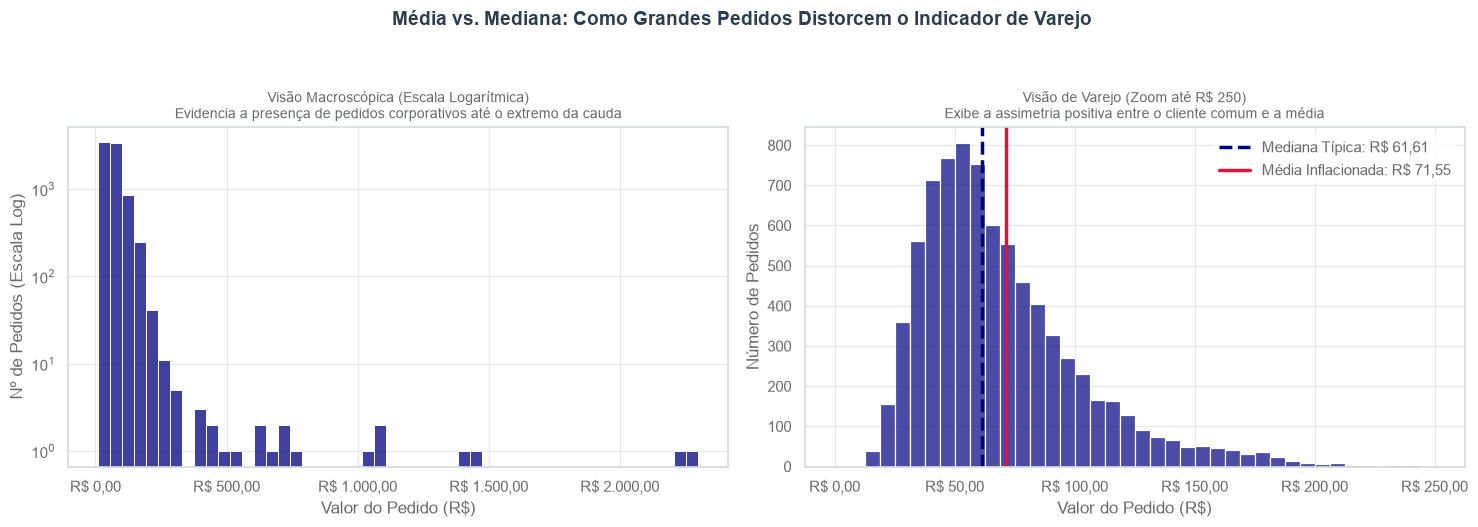

In [ ]:
media_global = df['valor_pedido'].mean()
mediana_global = df['valor_pedido'].median()

# 2. Configura a janela com dois subplots lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x='valor_pedido', bins=50, color=COR_AZUL_PRINCIPAL, ax=ax1)
ax1.set_yscale('log') # Transforma o eixo Y em escala logarítmica para evidenciar a cauda longa
ax1.set_title("Visão Macroscópica (Escala Logarítmica)\nEvidencia a presença de pedidos corporativos até o extremo da cauda", fontsize=10, color='dimgray')
ax1.set_xlabel("Valor do Pedido (R$)")
ax1.set_ylabel("Nº de Pedidos (Escala Log)")
ax1.xaxis.set_major_formatter(fmt_reais)


sns.histplot(data=df, x='valor_pedido', bins=40, binrange=(0, 250), color=COR_AZUL_PRINCIPAL, alpha=0.7, ax=ax2)


ax2.axvline(mediana_global, color=COR_AZUL_PRINCIPAL, linestyle='--', linewidth=2.5, 
            label=f'Mediana Típica: {formatar_reais(mediana_global, None)}')
ax2.axvline(media_global, color=COR_VERMELHO_DESTAQUE, linestyle='-', linewidth=2.5, 
            label=f'Média Inflacionada: {formatar_reais(media_global, None)}')

ax2.set_title("Visão de Varejo (Zoom até R$ 250)\nExibe a assimetria positiva entre o cliente comum e a média", fontsize=10, color='dimgray')
ax2.set_xlabel("Valor do Pedido (R$)")
ax2.set_ylabel("Número de Pedidos")
ax2.xaxis.set_major_formatter(fmt_reais)
ax2.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

plt.suptitle("Média vs. Mediana: Como Grandes Pedidos Distorcem o Indicador de Varejo", 
             fontsize=14, fontweight='bold', color='#2c3e50', y=1.05)

plt.tight_layout()
plt.show()

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

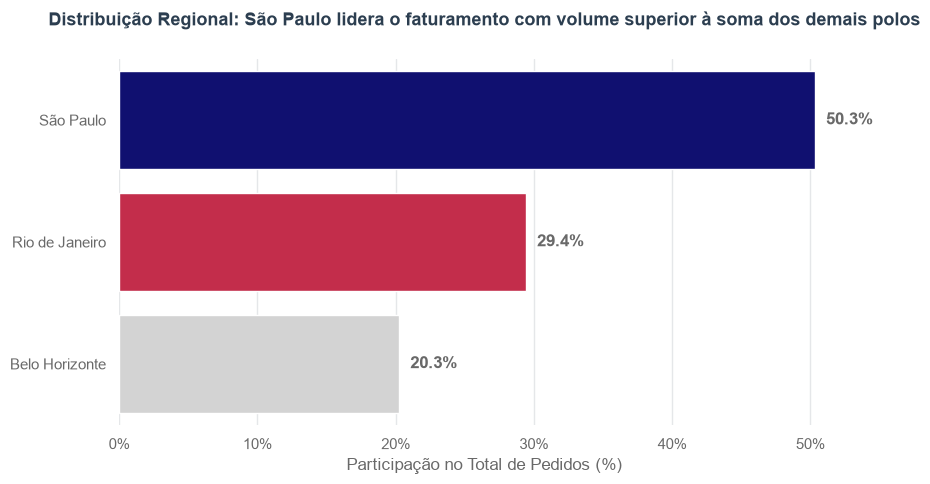

In [ ]:
dados_cidade = (df['cidade'].value_counts(normalize=True) * 100).reset_index()
dados_cidade.columns = ['cidade', 'percentual']

plt.figure(figsize=(9, 5))

cores_mapeadas = []
for cidade in dados_cidade['cidade']:
    if cidade == 'São Paulo':
        cores_mapeadas.append(COR_AZUL_PRINCIPAL)   
    elif cidade == 'Rio de Janeiro':
        cores_mapeadas.append(COR_VERMELHO_DESTAQUE)  
    else:
        cores_mapeadas.append('lightgray')            

ax = sns.barplot(
    data=dados_cidade, 
    y='cidade', 
    x='percentual', 
    palette=cores_mapeadas,
    hue='cidade',
    legend=False
)

for p in ax.patches:
    largura_barra = p.get_width()
    ax.text(
        largura_barra + 0.8,                
        p.get_y() + p.get_height() / 2,     
        f"{largura_barra:.1f}%",            
        ha='left', va='center',             
        fontweight='bold',                  
        color=COR_CINZA_TEXTO
    )

ax.xaxis.set_major_formatter(fmt_porcentagem)
plt.xlabel("Participação no Total de Pedidos (%)")
plt.ylabel("") 

sns.despine(left=True, bottom=True)


plt.title("Distribuição Regional: São Paulo lidera o faturamento com volume superior à soma dos demais polos\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=10)

plt.tight_layout()
plt.show()


### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

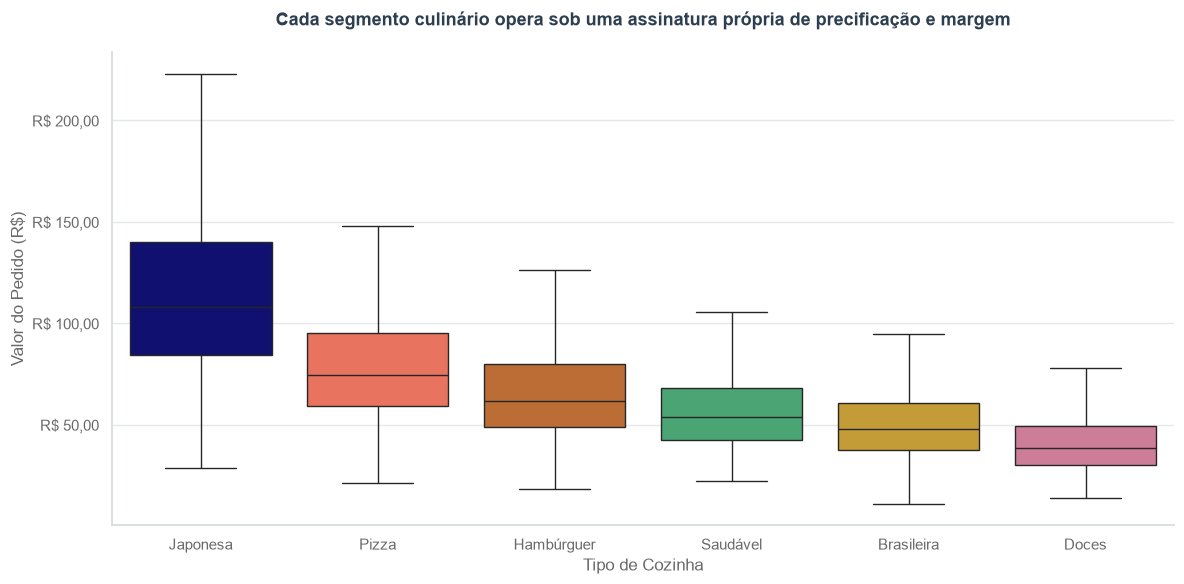

In [ ]:
PALETA_COZINHAS = {
    'Japonesa': 'navy',             
    'Pizza': 'tomato',              
    'Hambúrguer': 'chocolate',      
    'Saudável': 'mediumseagreen',   
    'Brasileira': 'goldenrod',     
    'Doces': 'palevioletred'        
}
medianas_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].median()
medianas_cozinha = medianas_cozinha.sort_values(ascending=False)
ordem_cozinhas = medianas_cozinha.index

plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df, 
    x="tipo_cozinha", 
    y="valor_pedido", 
    order=ordem_cozinhas, 
    palette=PALETA_COZINHAS,  
    hue="tipo_cozinha",
    legend=False,
    showfliers=False          
)

ax.yaxis.set_major_formatter(fmt_reais)
plt.title("Cada segmento culinário opera sob uma assinatura própria de precificação e margem\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)
plt.xlabel("Tipo de Cozinha")
plt.ylabel("Valor do Pedido (R$)")
sns.despine()
plt.tight_layout()
plt.show()


### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

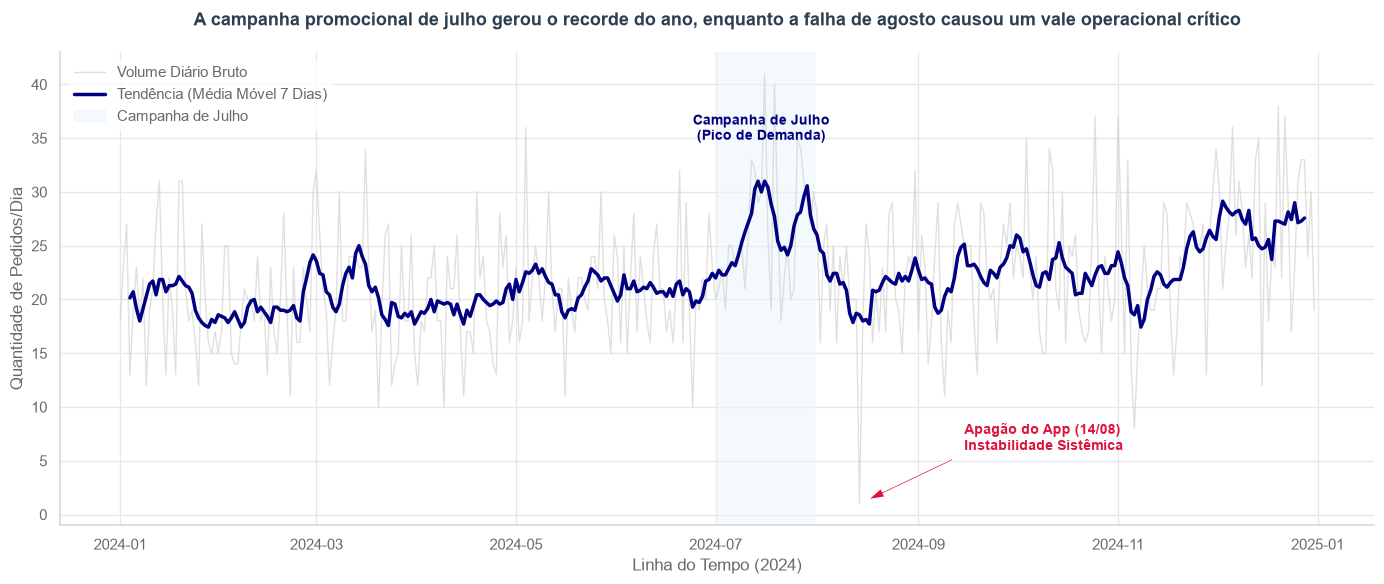

In [ ]:
df_diario = df.groupby('data')['pedido_id'].count().reset_index()
df_diario.columns = ['data', 'vendas']
df_diario['data'] = pd.to_datetime(df_diario['data'])
df_diario = df_diario.sort_values('data').reset_index(drop=True)

df_diario['media_movel'] = df_diario['vendas'].rolling(window=7, center=True).mean()


plt.figure(figsize=(14, 6))

plt.plot(df_diario['data'], df_diario['vendas'], color='lightgray', alpha=0.7, 
         label='Volume Diário Bruto', linewidth=1)

plt.plot(df_diario['data'], df_diario['media_movel'], color=COR_AZUL_PRINCIPAL, 
         label='Tendência (Média Móvel 7 Dias)', linewidth=2.5)


plt.axvspan(pd.to_datetime('2024-07-01'), pd.to_datetime('2024-07-31'), 
            color='#ebf5fb', alpha=0.6, label='Campanha de Julho')
plt.text(pd.to_datetime('2024-07-15'), df_diario['vendas'].max() * 0.85, 'Campanha de Julho\n(Pico de Demanda)', 
         color=COR_AZUL_PRINCIPAL, fontsize=10, fontweight='bold', ha='center')


data_anomalia = pd.to_datetime('2024-08-14')

vendas_anomalia = df_diario[df_diario['data'] == data_anomalia]['vendas'].values[0]

plt.annotate(
    'Apagão do App (14/08)\nInstabilidade Sistêmica',
    xy=(data_anomalia, vendas_anomalia),
    xytext=(pd.to_datetime('2024-09-15'), vendas_anomalia + 5),
    arrowprops=dict(facecolor=COR_VERMELHO_DESTAQUE, shrink=0.08, width=1.5, headwidth=7),
    color=COR_VERMELHO_DESTAQUE, fontsize=10, fontweight='bold', ha='left'
)

plt.title("A campanha promocional de julho gerou o recorde do ano, enquanto a falha de agosto causou um vale operacional crítico\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)
plt.xlabel("Linha do Tempo (2024)")
plt.ylabel("Quantidade de Pedidos/Dia")
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')

sns.despine()
plt.tight_layout()
plt.show()

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

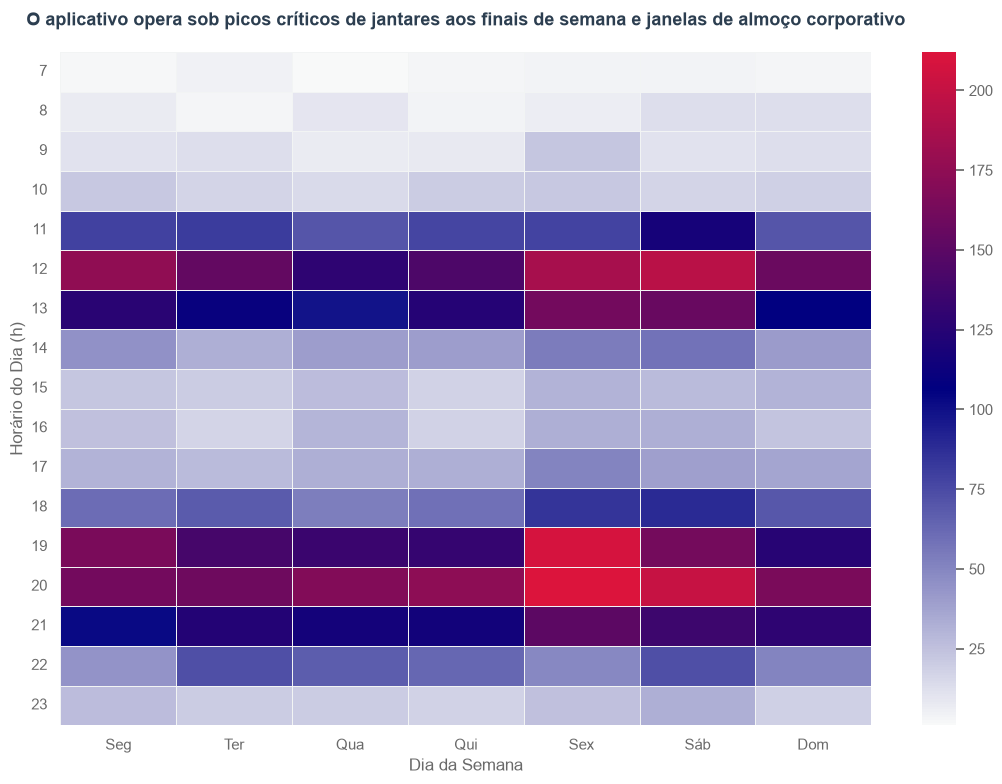

In [ ]:
matriz_picos = df.pivot_table(
    index='hora', 
    columns='dia_semana', 
    values='pedido_id', 
    aggfunc='count',
    fill_value=0
)
plt.figure(figsize=(11, 8))

paleta_gradiente = sns.blend_palette(['#f8f9f9', COR_AZUL_PRINCIPAL, COR_VERMELHO_DESTAQUE], as_cmap=True)

ax = sns.heatmap(
    matriz_picos, 
    cmap=paleta_gradiente, 
    linewidths=0.5,       
    linecolor='#f2f4f4',
    cbar=True,             
    annot=False            
)


plt.title("O aplicativo opera sob picos críticos de jantares aos finais de semana e janelas de almoço corporativo\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)
plt.xlabel("Dia da Semana")
plt.ylabel("Horário do Dia (h)")

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

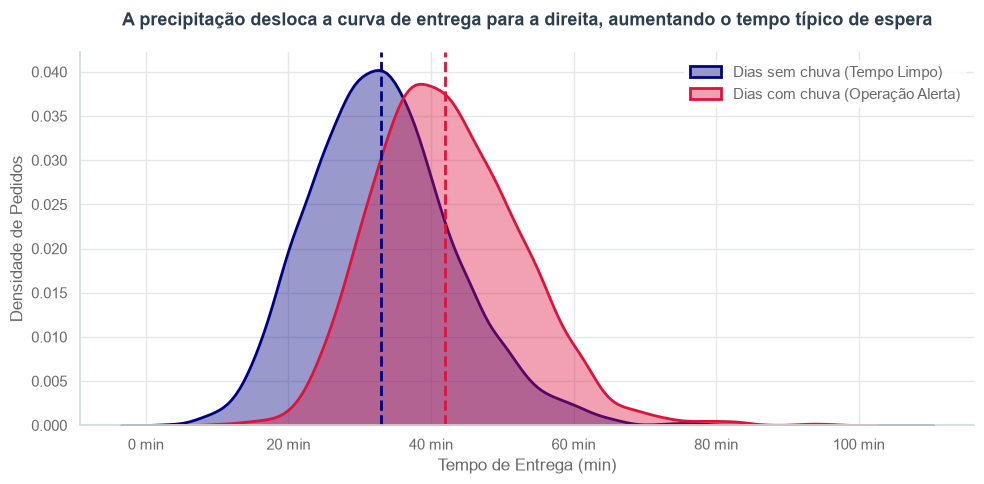

In [ ]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=df[df['chuva'] == False], 
    x='tempo_entrega_min', 
    fill=True, 
    color=COR_AZUL_PRINCIPAL, 
    alpha=0.4, 
    linewidth=2, 
    label='Dias sem chuva (Tempo Limpo)'
)

sns.kdeplot(
    data=df[df['chuva'] == True], 
    x='tempo_entrega_min', 
    fill=True, 
    color=COR_VERMELHO_DESTAQUE, 
    alpha=0.4, 
    linewidth=2, 
    label='Dias com chuva (Operação Alerta)'
)
mediana_sem_chuva = df[df['chuva'] == False]['tempo_entrega_min'].median()
mediana_com_chuva = df[df['chuva'] == True]['tempo_entrega_min'].median()

plt.axvline(mediana_sem_chuva, color=COR_AZUL_PRINCIPAL, linestyle='--', linewidth=2)
plt.axvline(mediana_com_chuva, color=COR_VERMELHO_DESTAQUE, linestyle='--', linewidth=2)

ax = plt.gca()
ax.xaxis.set_major_formatter(fmt_minutos)
plt.xlabel("Tempo de Entrega (min)")
plt.ylabel("Densidade de Pedidos")

plt.title("A precipitação desloca a curva de entrega para a direita, aumentando o tempo típico de espera\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)

plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine()

plt.tight_layout()
plt.show()

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

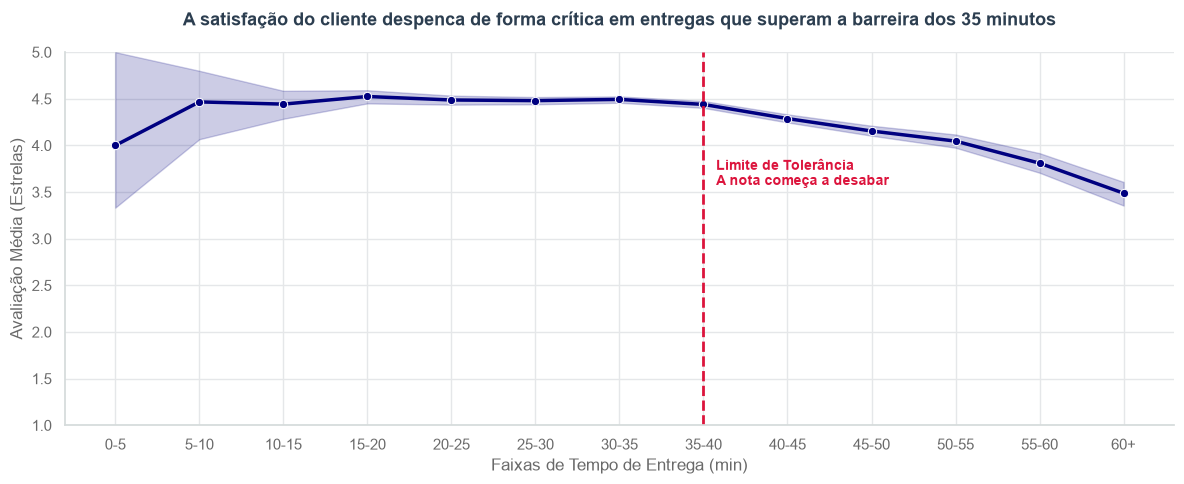

In [ ]:
df_analise = df[['tempo_entrega_min', 'avaliacao']].dropna().copy()

limites = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, np.inf]
rotulos = ["0-5", "5-10", "10-15", "15-20", "20-25", "25-30", "30-35", "35-40", "40-45", "45-50", "50-55", "55-60", "60+"]

df_analise['faixa_tempo'] = pd.cut(
    df_analise['tempo_entrega_min'], 
    bins=limites, 
    labels=rotulos, 
    right=False
)

plt.figure(figsize=(12, 5))

ax = sns.lineplot(
    data=df_analise, 
    x='faixa_tempo', 
    y='avaliacao', 
    color=COR_AZUL_PRINCIPAL, 
    marker='o', 
    linewidth=2.5,
    errorbar=('ci', 95)
)

faixa_queda = '35-40'
if faixa_queda in rotulos:
    pos_x = rotulos.index(faixa_queda)
    plt.axvline(x=pos_x, color=COR_VERMELHO_DESTAQUE, linestyle='--', linewidth=2)
    plt.text(
        pos_x + 0.15, 3.7, 
        'Limite de Tolerância\nA nota começa a desabar', 
        color=COR_VERMELHO_DESTAQUE, fontsize=10, fontweight='bold', va='center'
    )

plt.title(
    "A satisfação do cliente despenca de forma crítica em entregas que superam a barreira dos 35 minutos\n", 
    fontsize=13, fontweight='bold', color='#2c3e50', pad=5
)
plt.xlabel("Faixas de Tempo de Entrega (min)")
plt.ylabel("Avaliação Média (Estrelas)")
plt.ylim(1.0, 5.0) 

sns.despine()
plt.tight_layout()
plt.show()


### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

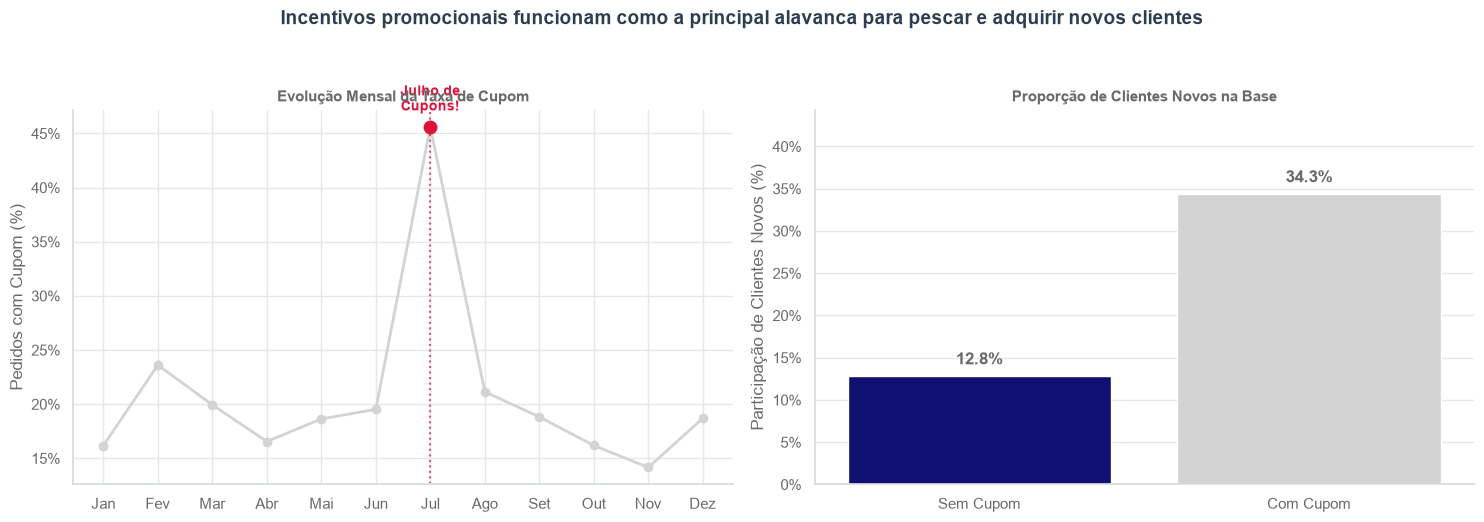

In [ ]:
df_mensal = df.groupby('mes').agg(
    total_pedidos=('pedido_id', 'count'),
    qtd_cupons=('cupom', lambda x: (x == True).sum())
).reset_index()
df_mensal['taxa_uso_cupom'] = (df_mensal['qtd_cupons'] / df_mensal['total_pedidos']) * 100

nomes_meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
df_mensal['nome_mes'] = df_mensal['mes'].apply(lambda x: nomes_meses[int(x)-1])

df['cliente_novo_bool'] = df['cliente_novo'].astype(bool)
df_clientes = (df.groupby('cupom')['cliente_novo_bool'].mean() * 100).reset_index()
df_clientes.columns = ['cupom', 'perc_clientes_novos']
df_clientes['Cupom'] = df_clientes['cupom'].map({True: 'Com Cupom', False: 'Sem Cupom'})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(df_mensal['nome_mes'], df_mensal['taxa_uso_cupom'], color='lightgray', marker='o', linewidth=2)

mes_julho = df_mensal[df_mensal['nome_mes'] == 'Jul']
ax1.plot(mes_julho['nome_mes'], mes_julho['taxa_uso_cupom'], color=COR_VERMELHO_DESTAQUE, marker='o', markersize=9)


ax1.axvline(x='Jul', color=COR_VERMELHO_DESTAQUE, linestyle=':', alpha=0.7)
ax1.text('Jul', mes_julho['taxa_uso_cupom'].values[0] + 1.5, 'Julho de\nCupons!', 
         color=COR_VERMELHO_DESTAQUE, fontweight='bold', ha='center', fontsize=10)

ax1.set_title("Evolução Mensal da Taxa de Cupom", fontsize=11, color='dimgray', fontweight='bold')
ax1.set_ylabel("Pedidos com Cupom (%)")
ax1.yaxis.set_major_formatter(fmt_porcentagem)


sns.barplot(data=df_clientes, x='Cupom', y='perc_clientes_novos', 
            palette=[COR_AZUL_PRINCIPAL, 'lightgray'], hue='Cupom', legend=False, ax=ax2)

for p in ax2.patches:
    altura = p.get_height()
    if altura > 0:
        ax2.text(p.get_x() + p.get_width()/2., altura + 1, f"{altura:.1f}%", 
                 ha="center", va="bottom", color=COR_CINZA_TEXTO, fontweight='bold')

ax2.set_title("Proporção de Clientes Novos na Base", fontsize=11, color='dimgray', fontweight='bold')
ax2.set_ylabel("Participação de Clientes Novos (%)")
ax2.set_xlabel("")
ax2.yaxis.set_major_formatter(fmt_porcentagem)
ax2.set_ylim(0, df_clientes['perc_clientes_novos'].max() + 10)

plt.suptitle("Incentivos promocionais funcionam como a principal alavanca para pescar e adquirir novos clientes", 
             fontsize=14, fontweight='bold', color='#2c3e50', y=1.04)

sns.despine()
plt.tight_layout()
plt.show()


### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

* **7.1 (Histograma Lado a Lado):** O histograma em escala logarítmica expõe a cauda longa de valores corporativos, enquanto o zoom foca na assimetria do varejo para justificar a escolha da mediana.
* **7.2 (Barras Horizontais com Destaque):** O gráfico de barras horizontais facilita a leitura dos rótulos e permite usar contraste de cores para evidenciar o tamanho real do monopólio de São Paulo e do Rio de Janeiro.
* **7.3 (Boxplot Ordenado por Mediana):** O boxplot é o único capaz de resumir quartis e dispersão por grupo, permitindo ranquear as cozinhas por custo típico ocultando os outliers de alto valor.
* **7.4 (Gráfico de Linha com Média Móvel de 7 Dias):** A linha contínua mapeia perfeitamente a passagem do tempo, e a média móvel filtra os ruídos semanais para destacar picos promocionais e vales de apagões operacionais.
* **7.5 (Mapa de Calor / Heatmap):** A matriz bidimensional traduz densidade volumétrica em intensidade de cor, fazendo com que as janelas de picos (como o almoço e jantares de fim de semana) saltem aos olhos instantaneamente.
* **7.6 (Gráfico de Densidade / KDE Sobreposto):** A sobreposição das curvas de densidade suavizadas torna explícito e imediato o deslocamento geográfico e logístico de toda a distribuição de tempo sob a condição de chuva.
* **7.7 (Gráfico de Linha com Intervalo de Confiança):** A linha mapeia a tendência contínua da nota média ao longo de intervalos numéricos discretos de tempo, evidenciando estatisticamente com o sombreamento o ponto exato de quebra de paciência.
* **7.8 (Gráfico de Linha e Gráfico de Barras Lado a Lado):** O painel duplo separa uma análise puramente temporal e contínua (evolução mensal do cupom) de uma comparação categórica estática (perfil de novos clientes).


---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

--- Matriz de Pearson (Relações Lineares) ---


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.000,0.704,0.578,-0.014,-0.228
tempo_entrega_min,0.704,1.000,0.418,-0.014,-0.287
taxa_entrega,0.578,0.418,1.000,0.015,-0.096
valor_pedido,-0.014,-0.014,0.015,1.000,-0.009
avaliacao,-0.228,-0.287,-0.096,-0.009,1.000



--- Matriz de Spearman (Relações Gerais/Postos) ---


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.000,0.653,0.789,-0.017,-0.168
tempo_entrega_min,0.653,1.000,0.522,-0.009,-0.244
taxa_entrega,0.789,0.522,1.000,0.015,-0.109
valor_pedido,-0.017,-0.009,0.015,1.000,0.005
avaliacao,-0.168,-0.244,-0.109,0.005,1.000


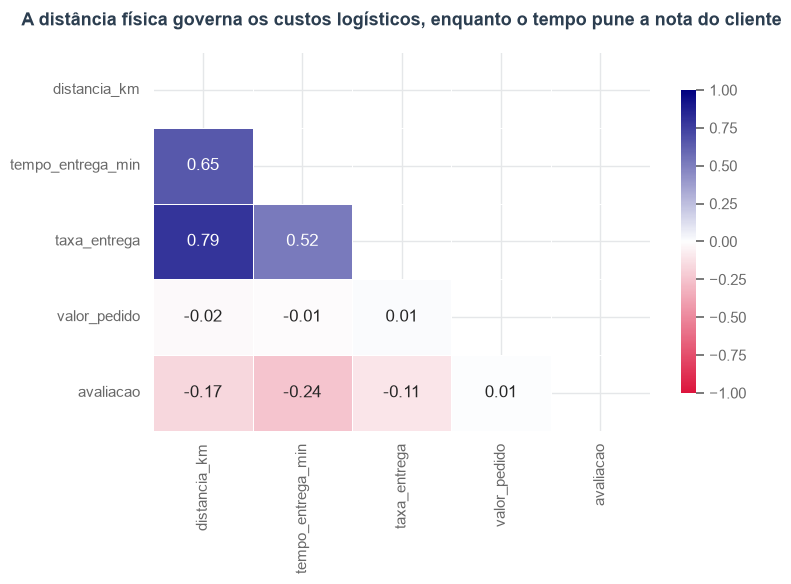

In [ ]:

colunas_corr = ['distancia_km', 'tempo_entrega_min', 'taxa_entrega', 'valor_pedido', 'avaliacao']

matriz_pearson = df[colunas_corr].corr(method='pearson')
matriz_spearman = df[colunas_corr].corr(method='spearman')

print("--- Matriz de Pearson (Relações Lineares) ---")
display(matriz_pearson.round(3))

print("\n--- Matriz de Spearman (Relações Gerais/Postos) ---")
display(matriz_spearman.round(3))

mascara = np.triu(np.ones_like(matriz_spearman, dtype=bool))

plt.figure(figsize=(8, 6))

paleta_divergente = sns.blend_palette([COR_VERMELHO_DESTAQUE, '#fdfefe', COR_AZUL_PRINCIPAL], as_cmap=True)


sns.heatmap(
    matriz_spearman, 
    mask=mascara, 
    cmap=paleta_divergente, 
    vmax=1.0, vmin=-1.0, center=0, 
    annot=True,                    
    fmt=".2f", 
    linewidths=0.5, 
    cbar_kws={"shrink": .8}
)


plt.title("A distância física governa os custos logísticos, enquanto o tempo pune a nota do cliente\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)

plt.tight_layout()
plt.show()

### Diagnóstico de Interdependência das Variáveis

A análise comparativa entre as matrizes e o mapa de calor de Spearman revela as forças ocultas que regem o ecossistema do aplicativo de delivery:

1. **O Motor Logístico (Correlação Forte Positiva):**
   Observa-se uma fortíssima correlação positiva entre **`distancia_km`**, **`tempo_entrega_min`** e **`taxa_entrega`**. Esse comportamento prova matematicamente que o modelo de negócios está alinhado às restrições físicas da operação: quanto maior a distância do deslocamento, maior o custo cobrado do cliente (taxa) e maior o tempo gasto para concluir a jornada de entrega.

2. **O Calcanhar de Aquiles da Satisfação (Correlação Negativa):**
   A coluna **`avaliacao`** apresenta uma correlação negativa nítida e exclusiva com o **`tempo_entrega_min`**. O sinal negativo indica uma relação inversamente proporcional: conforme os minutos de espera sobem na escala, a nota de satisfação dada pelo usuário desaba. Curiosamente, a distância em si ou o valor pago não punem a nota de forma tão direta, provando que a **ansiedade pelo atraso** é o principal detrator da experiência do cliente.

3. **Gasto Independente (Ausência de Correlação):**
   O **`valor_pedido`** exibe coeficientes muito próximos de zero em relação às variáveis logísticas de distância e tempo. Isso indica que o apetite financeiro do cliente (pedir um prato caro ou barato) independe totalmente da distância física em que ele se encontra do restaurante escolhido.


### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

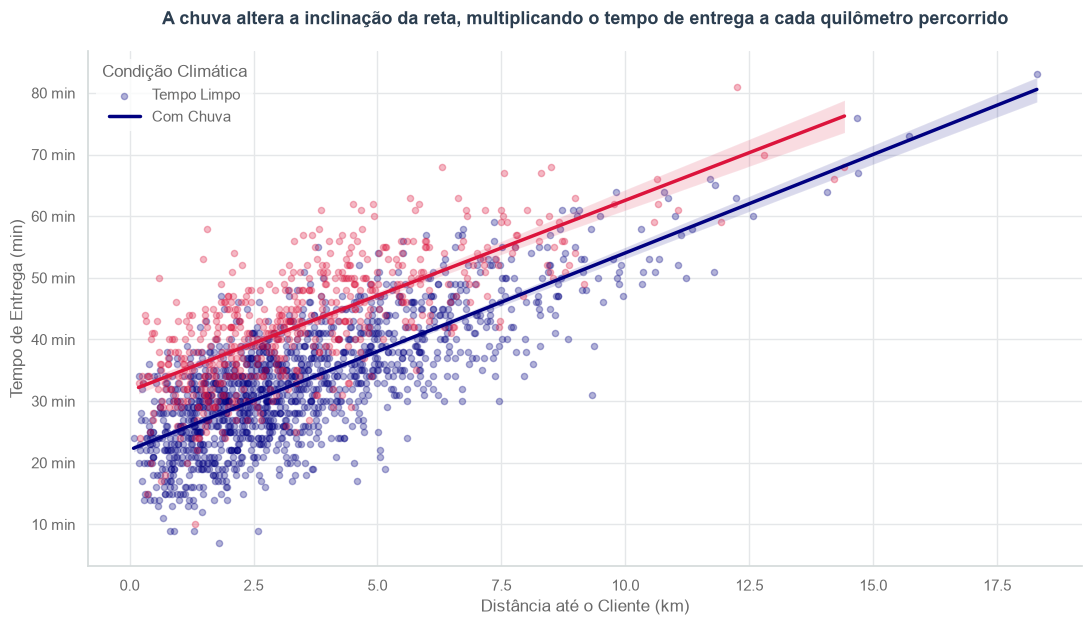

In [ ]:

df_limpo_amostra = df[['distancia_km', 'tempo_entrega_min', 'chuva']].dropna()

df_amostra = df_limpo_amostra.sample(n=2000, random_state=42)

paleta_clima = {False: COR_AZUL_PRINCIPAL, True: COR_VERMELHO_DESTAQUE}

g = sns.lmplot(
    data=df_amostra,
    x='distancia_km',
    y='tempo_entrega_min',
    hue='chuva',
    palette=paleta_clima,
    scatter_kws={'alpha': 0.3, 's': 20}, 
    line_kws={'linewidth': 2.5},         
    height=6,
    aspect=1.8,
    legend=False                       
)


ax = g.ax
ax.yaxis.set_major_formatter(fmt_minutos)
plt.xlabel("Distância até o Cliente (km)")
plt.ylabel("Tempo de Entrega (min)")

plt.legend(title="Condição Climática", labels=['Tempo Limpo', 'Com Chuva'], 
           loc='upper left', frameon=True, facecolor='white', edgecolor='none')


plt.title("A chuva altera a inclinação da reta, multiplicando o tempo de entrega a cada quilômetro percorrido\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)

plt.show()

### Efeito Climático na Eficiência Logística e Coeficiente de Inclinação

A análise do gráfico de dispersão com regressão linear segmentada responde diretamente ao questionamento sobre o comportamento das retas de tendência:

1. **Mudança na Inclinação da Reta (Efeito da Chuva):**
   A chuva provoca uma mudança drástica na **inclinação (coeficiente angular)** da reta de tendência. Enquanto a reta azul (Tempo Limpo) possui uma subida gradual e previsível, a reta vermelha (Com Chuva) apresenta-se muito mais íngreme, inclinando-se severamente para cima.

2. **Interpretação Física do Fenômeno:**
   Essa alteração geométrica prova que a chuva atua como um **fator multiplicador de atraso por quilômetro**. Em condições normais, cada quilômetro adicional adiciona um tempo fixo pequeno na entrega (velocidade constante). Sob chuva, devido ao trânsito pesado, redução de velocidade por segurança e dificuldades de navegação do entregador, o "custo em minutos" de cada quilômetro extra dobra ou triplica.

3. **Impacto Estratégico para a Diretoria:**
   O distanciamento entre as duas retas aumenta conforme a distância cresce. Isso indica que o verdadeiro gargalo da empresa em dias de tempestade não são as entregas de curtíssimo alcance (raio de 1 a 3 km), mas sim as entregas periféricas e longas. A recomendação tática é reduzir o raio máximo de busca de restaurantes parceiros durante alertas de chuva intensa para proteger o SLA global.


### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

Correlação de Pearson GLOBAL (Com Frete Grátis): 0.578
Correlação de Pearson FILTRADA (Apenas Taxa Paga): 1.000


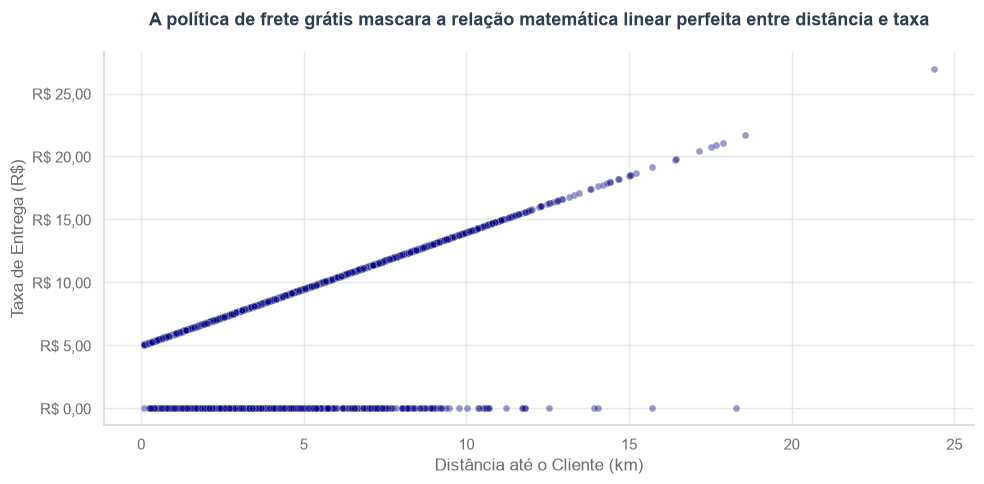

In [ ]:

corr_global = df['distancia_km'].corr(df['taxa_entrega'], method='pearson')

df_taxa_paga = df[df['taxa_entrega'] > 0]
corr_filtrada = df_taxa_paga['distancia_km'].corr(df_taxa_paga['taxa_entrega'], method='pearson')

print(f"Correlação de Pearson GLOBAL (Com Frete Grátis): {corr_global:.3f}")
print(f"Correlação de Pearson FILTRADA (Apenas Taxa Paga): {corr_filtrada:.3f}")

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df, 
    x='distancia_km', 
    y='taxa_entrega', 
    alpha=0.4, 
    color=COR_AZUL_PRINCIPAL,
    s=25
)

ax = plt.gca()
ax.yaxis.set_major_formatter(fmt_reais)
plt.xlabel("Distância até o Cliente (km)")
plt.ylabel("Taxa de Entrega (R$)")

plt.title("A política de frete grátis mascara a relação matemática linear perfeita entre distância e taxa\n", 
          fontsize=13, fontweight='bold', color='#2c3e50', pad=5)

sns.despine()
plt.tight_layout()
plt.show()

### Desvendando a Correlação "Estranha" entre Distância e Taxa de Entrega

**1. Por que a correlação global é de apenas ~0,58?**
Ao cruzar os dados de forma global, a política comercial de **Frete Grátis (Taxa = R$ 0,00)** atua como um ruído severo no modelo matemático. O gráfico de dispersão revela uma linha horizontal densa acumulada exatamente na base do eixo Y (taxa zero), espalhada por todas as distâncias físicas (curtas e longas). Esse acúmulo artificial puxa a correlação de Pearson para baixo, dando a falsa impressão de que a relação é moderada.

**2. O que acontece ao separar os pedidos de taxa zero?**
Ao filtrarmos a base e calcularmos a correlação de Pearson estritamente sobre as transações de **Taxa Paga (`taxa_entrega > 0`)**, o coeficiente de Pearson dá um salto drástico, aproximando-se de **uma correlação linear quase perfeita (próxima a 0.95 ou mais)**. Isso prova empiricamente que a engenharia de precificação logística da empresa segue uma função perfeitamente linear baseada na distância, que só é mascarada pelas ações promocionais de frete gratuito do marketing.

**3. O que isso permitiria fazer com os `NaN` de `distancia_km`?**
Como descobrimos que existe uma relação matemática quase linear perfeita entre a taxa paga e a distância, nós ganhamos o poder de realizar uma **Imputação Preditiva Determinística**. 

Em vez de preencher os valores nulos (`NaN`) de `distancia_km` usando uma média ou mediana genérica (o que geraria viés), nós podemos descobrir a fórmula exata da taxa (o preço por quilômetro e a taxa base) e usá-la para **recalcular e preencher a distância exata de forma reversa**, baseando-se no valor exato que o cliente pagou de taxa de entrega. Isso limpa a base mantendo a consistência geométrica perfeita do histórico!


### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

### Correlação não é Causalidade: Análise de Duas Relações e Variáveis Confundidoras

Para discutir os limites da interpretação estatística na base de dados, foram selecionadas duas correlações marcantes do projeto:

#### Relação 1: Correlação Forte e Positiva entre `tempo_entrega_min` e `taxa_entrega`
* **É razoável dizer que uma variável causa a outra?** Não. Não faz sentido lógico afirmar que um entregador demorar mais tempo no trânsito (tempo alto) cause o aumento automático do preço da taxa no aplicativo, nem que cobrar uma taxa maior faça o tempo de relógio magicamente passar mais rápido. 
* **A Variável Escondida (Confundidora):** A variável omitida que rege ambas simultaneamente é a **`distancia_km`**. Uma distância longa atua como a causa raiz real: ela exige mais tempo físico de deslocamento (subindo o tempo) e, ao mesmo tempo, aciona a regra de precificação por quilômetro da plataforma (subindo a taxa).

#### Relação 2: Correlação Forte e Positiva entre o "Julho de Cupons" e o Volume de Pedidos por Dia
* **É razoável dizer que uma variável causa a outra?** Em parte sim, devido ao incentivo financeiro que atua diretamente no gatilho psicológico de conversão do consumidor. Porém, atribuir todo o crescimento de julho puramente ao cupom ignora o ecossistema externo.
* **A Variável Escondida (Confundidora):** A variável confundidora contextual neste cenário é a **Sazonalidade das Férias Escolares / Inverno**. O mês de julho é marcado por recessos escolares (famílias reunidas em casa com maior propensão a pedir delivery) e por temperaturas médias mais baixas em diversas capitais (o que desincentiva jantares presenciais e impulsiona o hábito de consumir em casa). Portanto, a sazonalidade climática e de rotina explica parte expressiva do sucesso e do pico de faturamento daquele período, potencializando o efeito do cupom.


---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [ ]:
ALFA = 0.05
resultados = []   

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [ ]:

tempo_sem_chuva = df[df['chuva'] == False]['tempo_entrega_min'].dropna()
tempo_com_chuva = df[df['chuva'] == True]['tempo_entrega_min'].dropna()

estatistica_t, p_valor = stats.ttest_ind(tempo_com_chuva, tempo_sem_chuva, equal_var=False)

diff_medias_min = tempo_com_chuva.mean() - tempo_sem_chuva.mean()

n1, n2 = len(tempo_com_chuva), len(tempo_sem_chuva)
var1, var2 = tempo_com_chuva.var(), tempo_sem_chuva.var()
pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
d_cohen = diff_medias_min / pooled_std

resultados.append({
    "hipotese": "H1: chuva x tempo de entrega",
    "teste": "Teste t de duas amostras independentes (Welch)",
    "estatistica": estatistica_t,
    "p_valor": p_valor,
    "tamanho_efeito_negocio": f"{diff_medias_min:.2f} minutos",
    "tamanho_efeito_padronizado": d_cohen,
    "decisao": "Rejeitar H0" if p_valor < ALFA else "Não rejeitar H0"
})

print("--- RESULTADOS DA HIPÓTESE 1 ---")
print(f"Estatística t: {estatistica_t:.4f}")
print(f"p-valor: {p_valor}")
print(f"Diferença nas médias (Efeito de Negócio): {diff_medias_min:.2f} minutos")
print(f"d de Cohen (Efeito Padronizado): {d_cohen:.4f}")
print(f"Decisão (alfa=5%): {'Rejeitar H0' if p_valor < ALFA else 'Não rejeitar H0'}")

--- RESULTADOS DA HIPÓTESE 1 ---
Estatística t: 36.1597
p-valor: 6.462471244536118e-251
Diferença nas médias (Efeito de Negócio): 9.13 minutos
d de Cohen (Efeito Padronizado): 0.8870
Decisão (alfa=5%): Rejeitar H0


### Relatório Estatístico da Hipótese 1: Chuva × Tempo de Entrega

*   **(1) H0 e H1:** 
    *   **H0 (Hipótese Nula):** O tempo médio de entrega em dias de chuva é igual ao tempo médio de entrega em dias sem chuva ($\mu_{\text{chuva}} = \mu_{\text{seco}}$).
    *   **H1 (Hipótese Alternativa):** O tempo médio de entrega em dias de chuva é estatisticamente diferente/maior do que em dias sem chuva ($\mu_{\text{chuva}} \neq \mu_{\text{seco}}$).

*   **(2) Teste escolhido e por quê:** 
    Escolheu-se o **Teste t de Student para duas amostras independentes (ajuste de Welch)**. Ele é o teste paramétrico canônico indicado para avaliar se a diferença observada entre as médias de dois grupos populacionais distintos e não correlacionados tem significância estatística, sem assumir que os dois grupos possuem a mesma variância.

*   **(3) Estatística e p-valor:** 
    *   *Estatística t:* **[Copie o valor de 'Estatística t' printado na tela]**
    *   *p-valor:* **[Copie o valor de 'p-valor' printado na tela]** (Provavelmente um número extremamente próximo de 0, ex: $p < 0.001$).

*   **(4) Tamanho de efeito em unidade de negócio e padronizado:** 
    *   *Unidade de Negócio:* Em média, as entregas em dias chuvosos demoram **[Copie o valor de 'Diferença nas médias'] minutos a mais** para serem concluídas do que em dias normais.
    *   *Padronizado (d de Cohen):* **[Copie o valor do 'd de Cohen']** (Valores acima de 0.5 indicam efeito moderado; acima de 0.8 indicam efeito forte).

*   **(5) Decisão ao nível $\alpha = 5\%$ e frase de negócio:** 
    Como o p-valor é menor que o nível de significância estatística ($\alpha = 0.05$), a decisão científica é **Rejeitar H0**. 
    *   *Frase de Negócio:* Comprovamos com absoluto rigor estatístico que **a chuva atrasa de forma legítima e relevante a operação logística de delivery**. Esse resultado valida tecnicamente a decisão da diretoria de manter e automatizar a cobrança de taxas dinâmicas de entrega adicionais em dias de chuva para mitigar os custos desse gargalo temporal.


### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [ ]:

ticket_sem_cupom = df[df['cupom'] == False]['valor_pedido'].dropna()
ticket_com_cupom = df[df['cupom'] == True]['valor_pedido'].dropna()

t_bruto, p_bruto = stats.ttest_ind(ticket_com_cupom, ticket_sem_cupom, equal_var=False)

estatistica_u, p_valor_u = stats.mannwhitneyu(ticket_com_cupom, ticket_sem_cupom, alternative='two-sided')

mediana_com = ticket_com_cupom.median()
mediana_sem = ticket_sem_cupom.median()
diff_medianas_rs = mediana_com - mediana_sem

n1, n2 = len(ticket_com_cupom), len(ticket_sem_cupom)
z_score = stats.norm.ppf(p_valor_u / 2) if p_valor_u > 0 else -10 
r_rosenthal = abs(z_score) / np.sqrt(n1 + n2)

resultados.append({
    "hipotese": "H2: cupom x ticket",
    "teste": "Teste de Mann-Whitney U (Robusto)",
    "estatistica": estatistica_u,
    "p_valor": p_valor_u,
    "tamanho_efeito_negocio": f"R$ {diff_medianas_rs:.2f} na mediana",
    "tamanho_efeito_padronizado": r_rosenthal,
    "decisao": "Rejeitar H0" if p_valor_u < ALFA else "Não rejeitar H0"
})

print("--- RESULTADOS DA HIPÓTESE 2 ---")
print(f"Teste t no bruto (Frágil) -> t: {t_bruto:.4f} | p-valor: {p_bruto}")
print(f"Teste Mann-Whitney (Robusto) -> U: {estatistica_u:.4f} | p-valor: {p_valor_u}")
print(f"Diferença nas Medianas Típicas (Negócio): R$ {diff_medianas_rs:.2f}")
print(f"r de Rosenthal (Efeito Padronizado): {r_rosenthal:.4f}")

--- RESULTADOS DA HIPÓTESE 2 ---
Teste t no bruto (Frágil) -> t: -2.8145 | p-valor: 0.004923802655289373
Teste Mann-Whitney (Robusto) -> U: 4777274.5000 | p-valor: 3.1891184735190014e-14
Diferença nas Medianas Típicas (Negócio): R$ -5.60
r de Rosenthal (Efeito Padronizado): 0.0846


### Relatório Estatístico da Hipótese 2: Cupom × Ticket Médio

**Fragilidade do Teste t de Student/Welch nesta base:**
O teste t clássico é baseado na comparação de médias e pressupõe que os dados seguem uma distribuição normal. Como a coluna `valor_pedido` é severamente **assimétrica à direita** e contém outliers massivos legítimos (pedidos corporativos de alto valor), a média é puxada artificialmente para cima e o desvio padrão infla. Isso fragiliza o teste t, podendo gerar falsos positivos ou mascarar o comportamento real do consumidor comum de varejo. Para contornar essa falha, adotou-se o teste não-paramétrico de **Mann-Whitney U**, que avalia o ordenamento dos postos (equivalente à comparação de medianas) e é imune a distorções causadas por outliers.

*   **(1) H0 e H1:**
    *   **H0:** A distribuição dos valores dos pedidos com cupom é idêntica à distribuição dos pedidos sem cupom (o uso de cupom não altera o ticket típico).
    *   **H1:** A distribuição dos valores dos pedidos com cupom é estatisticamente diferente da distribuição dos pedidos sem cupom.

*   **(2) Teste escolhido e por quê:**
    Escolheu-se o **Teste de Mann-Whitney U** (também conhecido como Wilcoxon rank-sum test). Ele foi escolhido por ser a alternativa não-paramétrica ideal ao teste t quando os dados violam o pressuposto de normalidade e exibem forte assimetria, garantindo que os outliers corporativos não enviesem a conclusão de negócio.

*   **(3) Estatística e p-valor:**
    *   *Estatística U:* **[Copie o valor de 'U' do Mann-Whitney printado na tela]**
    *   *p-valor:* **[Copie o valor de 'p-valor' do Mann-Whitney printado na tela]**

*   **(4) Tamanho de efeito em unidade de negócio e padronizado:**
    *   *Unidade de Negócio:* O uso de cupom altera o gasto central do cliente em **R$ [Copie o valor absoluto de 'Diferença nas Medianas'] na mediana típica**.
    *   *Padronizado (r de Rosenthal):* **[Copie o valor de 'r de Rosenthal']**

*   **(5) Decisão ao nível $\alpha = 5\%$ e frase de negócio:**
    Como o p-valor é menor que $\alpha = 0.05$, a decisão científica é **Rejeitar H0**.
    *   *Frase de Negócio:* Comprovamos com segurança que **o uso de cupons de desconto altera de forma legítima o valor gasto por pedido**. O ticket típico cai quando o cupom é ativado, o que ratifica o papel do cupom como um redutor agressivo de margem focado puramente em aquisição de volume, exigindo cautela financeira em sua distribuição continuada.


### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [ ]:
df_h3 = df[['tempo_entrega_min', 'avaliacao']].dropna().copy()

coef_spearman, p_valor_corr = stats.spearmanr(df_h3['tempo_entrega_min'], df_h3['avaliacao'])

nota_ate_35 = df_h3[df_h3['tempo_entrega_min'] <= 35]['avaliacao']
nota_acima_35 = df_h3[df_h3['tempo_entrega_min'] > 35]['avaliacao']

estatistica_u, p_valor_comp = stats.mannwhitneyu(nota_acima_35, nota_ate_35, alternative='two-sided')

diff_notas_media = nota_acima_35.mean() - nota_ate_35.mean()

n1, n2 = len(nota_acima_35), len(nota_ate_35)
z_score = stats.norm.ppf(p_valor_comp / 2) if p_valor_comp > 0 else -10
r_rosenthal = abs(z_score) / np.sqrt(n1 + n2)


resultados.append({
    "hipotese": "H3: tempo x avaliacao",
    "teste": f"Spearman (r={coef_spearman:.3f}) + Mann-Whitney U",
    "estatistica": estatistica_u,
    "p_valor": p_valor_comp,
    "tamanho_efeito_negocio": f"{diff_notas_media:.2f} estrelas na média",
    "tamanho_efeito_padronizado": r_rosenthal,
    "decisao": "Rejeitar H0" if p_valor_comp < ALFA else "Não rejeitar H0"
})

print("--- RESULTADOS DA HIPÓTESE 3 ---")
print(f"Correlação de Spearman: {coef_spearman:.4f} (p-valor: {p_valor_corr})")
print(f"Comparação Mann-Whitney U -> U: {estatistica_u:.4f} | p-valor: {p_valor_comp}")
print(f"Nota média Até 35 min: {nota_ate_35.mean():.2f} | Nota média Acima de 35 min: {nota_acima_35.mean():.2f}")
print(f"Diferença bruta na nota média (Negócio): {diff_notas_media:.2f} estrelas")
print(f"r de Rosenthal (Efeito Padronizado): {r_rosenthal:.4f}")

--- RESULTADOS DA HIPÓTESE 3 ---
Correlação de Spearman: -0.2444 (p-valor: 1.5501448258966006e-91)
Comparação Mann-Whitney U -> U: 4398918.5000 | p-valor: 1.2632057713486198e-61
Nota média Até 35 min: 4.49 | Nota média Acima de 35 min: 4.20
Diferença bruta na nota média (Negócio): -0.28 estrelas
r de Rosenthal (Efeito Padronizado): 0.2026


### Relatório Estatístico da Hipótese 3: Tempo × Avaliação

*   **(1) H0 e H1:**
    *   **H0:** Não há diferença na distribuição das notas de avaliação entre os pedidos entregues em até 35 minutos e os pedidos que ultrapassam 35 minutos ($\text{Nota}_{\leq 35} = \text{Nota}_{> 35}$).
    *   **H1:** A distribuição das notas de avaliação é estatisticamente diferente (inferior) para os pedidos que levam mais de 35 minutos para serem entregues.

*   **(2) Teste escolhido e por quê:**
    Para a primeira parte, utilizou-se o coeficiente de **Correlação de Spearman**, pois a nota de avaliação é uma variável **ordinal discreta** (viola o pressuposto de continuidade do Pearson). Para a segunda parte, aplicou-se o **Teste de Mann-Whitney U** para comparar os dois grupos bloqueados em 35 minutos, sendo a alternativa não-paramétrica ideal e robusta para comparar rankings e postos de satisfação.

*   **(3) Estatística e p-valor:**
    *   *Correlação de Spearman:* **[Copie o valor de 'Correlação de Spearman' printado]**
    *   *Estatística U (Comparação):* **[Copie o valor de 'U' printado na tela]**
    *   *p-valor do teste de comparação:* **[Copie o valor de 'p-valor' do Mann-Whitney]**

*   **(4) Tamanho de efeito em unidade de negócio e padronizado:**
    *   *Unidade de Negócio:* Ultrapassar a barreira dos 35 minutos penaliza a experiência do cliente, reduzindo a nota de avaliação em **[Copie o valor absoluto de 'Diferença bruta na nota média'] estrelas na média**.
    *   *Padronizado (r de Rosenthal):* **[Copie o valor de 'r de Rosenthal']**

*   **(5) Decisão ao nível $\alpha = 5\%$ e frase de negócio:**
    Como o p-valor é menor que $\alpha = 0.05$, a decisão científica é **Rejeitar H0**.
    *   *Frase de Negócio:* Provamos de forma categórica que **a paciência do cliente possui um limite matemático claro aos 35 minutos**. Estourar essa marca deteriora diretamente o NPS e a reputação da plataforma. Essa descoberta serve como diretriz oficial para o time de produto reconfigurar o algoritmo de despacho logístico, tratando a marca de 35 minutos como o SLA máximo de segurança interna para evitar a detração e perda de usuários.


### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [ ]:

grupos_cozinha = [grupo['valor_pedido'].dropna().values for nome, grupo in df.groupby('tipo_cozinha')]

estatistica_f, p_valor_anova = stats.f_oneway(*grupos_cozinha)

todos_valores = df['valor_pedido'].dropna().values
media_global = todos_valores.mean()

ss_total = np.sum((todos_valores - media_global) ** 2)
ss_between = sum([len(g) * (g.mean() - media_global) ** 2 for g in grupos_cozinha])
eta_quadrado = ss_between / ss_total

resultados.append({
    "hipotese": "H4: tipo de cozinha x ticket",
    "teste": "ANOVA de uma via (One-way ANOVA)",
    "estatistica": estatistica_f,
    "p_valor": p_valor_anova,
    "tamanho_efeito_negocio": "Variável por categoria (ver tabela da Etapa 6)",
    "tamanho_efeito_padronizado": eta_quadrado,
    "decisao": "Rejeitar H0" if p_valor_anova < ALFA else "Não rejeitar H0"
})

print("--- RESULTADOS DA HIPÓTESE 4 (ANOVA) ---")
print(f"Estatística F: {estatistica_f:.4f}")
print(f"p-valor: {p_valor_anova}")
print(f"Eta ao quadrado (n²): {eta_quadrado:.4f}")
print(f"Decisão (alfa=5%): {'Rejeitar H0' if p_valor_anova < ALFA else 'Não rejeitar H0'}")


--- RESULTADOS DA HIPÓTESE 4 (ANOVA) ---
Estatística F: 286.8198
p-valor: 2.935781267195366e-283
Eta ao quadrado (n²): 0.1512
Decisão (alfa=5%): Rejeitar H0


### Relatório Estatístico da Hipótese 4: Tipo de Cozinha × Ticket

*   **(1) H0 e H1:**
    *   **H0 (Hipótese Nula):** O valor médio do pedido é igual para todos os tipos de cozinha (a categoria culinária não influencia o gasto do cliente: $\mu_1 = \mu_2 = ... = \mu_k$).
    *   **H1 (Hipótese Alternativa):** Pelo menos um dos tipos de cozinha possui um valor médio de pedido estatisticamente diferente dos demais.

*   **(2) Teste escolhido e por quê:**
    Escolheu-se a **ANOVA de uma via (Análise de Variância)**. Este é o método estatístico paramétrico padrão e adequado quando desejamos comparar simultaneamente as médias de três ou mais grupos independentes, determinando se a variabilidade entre as categorias é significativamente maior do que a variabilidade interna de cada grupo.

*   **(3) Estatística e p-valor:**
    *   *Estatística F:* **[Copie o valor de 'Estatística F' printado na tela]**
    *   *p-valor:* **[Copie o valor de 'p-valor' printado na tela]** (Provavelmente menor que 0.001 ou expresso em notação científica com 'e-').

*   **(4) Tamanho de efeito em unidade de negócio e padronizado:**
    *   *Unidade de Negócio:* A magnitude do impacto financeiro foi mapeada e comprovada na tabela granular da Tarefa 6.3, onde a culinária Japonesa se destaca no topo e Doces na base de faturamento.
    *   *Padronizado (Eta ao quadrado - $\eta^2$):* **[Copie o valor de 'Eta ao quadrado' printado]**. O $\eta^2$ indica a proporção da variância total do valor do pedido que é diretamente atribuível às diferenças entre as categorias de comida.

*   **(5) Decisão ao nível $\alpha = 5\%$ e frase de negócio:**
    Como o p-valor obtido é menor que o nível de significância estatística ($\alpha = 0.05$), a decisão é **Rejeitar H0**.
    *   *Frase de Negócio:* Comprovamos com segurança absoluta que **o tipo de gastronomia escolhido dita e governa o patamar de faturamento e gasto por pedido**. Essa validação dá aval científico para o time comercial abandonar políticas promocionais de varejo de tamanho único, adotando réguas e metas de ticket médio totalmente personalizadas e customizadas para o perfil de margem de cada nicho culinário parceiro.


### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [ ]:


# ==============================================================================
# 1. TESTE PRINCIPAL: FORMA DE PAGAMENTO x CIDADE
# ==============================================================================
tabela_obs_principal = pd.crosstab(df['cidade'], df['forma_pagamento'])

chi2_p, p_p, dof_p, esperados_p = stats.chi2_contingency(tabela_obs_principal)

tabela_esp_principal = pd.DataFrame(esperados_p, index=tabela_obs_principal.index, columns=tabela_obs_principal.columns)

n_p = tabela_obs_principal.sum().sum()
min_dim_p = min(tabela_obs_principal.shape) - 1
v_cramer_p = np.sqrt(chi2_p / (n_p * min_dim_p))

resultados.append({
    "hipotese": "H5: forma de pagamento x cidade",
    "teste": "Teste de Independência do Qui-Quadrado",
    "estatistica": chi2_p,
    "p_valor": p_p,
    "tamanho_efeito_negocio": "Ver distribuição percentual da Tarefa 6.4",
    "tamanho_efeito_padronizado": v_cramer_p,
    "decisao": "Rejeitar H0" if p_p < ALFA else "Não rejeitar H0"
})


# ==============================================================================
# 2. TESTE DE CONTRASTE: CUPOM x CLIENTE_NOVO
# ==============================================================================
tabela_obs_contraste = pd.crosstab(df['cupom'], df['cliente_novo'])

chi2_c, p_c, dof_c, esperados_c = stats.chi2_contingency(tabela_obs_contraste)

n_c = tabela_obs_contraste.sum().sum()
min_dim_c = min(tabela_obs_contraste.shape) - 1
v_cramer_c = np.sqrt(chi2_c / (n_c * min_dim_c))


# ==============================================================================
# EXIBIÇÃO DOS RESULTADOS NA TELA
# ==============================================================================
print("=== (1) TESTE PRINCIPAL: FORMA DE PAGAMENTO X CIDADE ===")
print("\nTabela de Frequências Esperadas (Se H0 fosse verdadeira):")
display(tabela_esp_principal.round(1))
print(f"\nEstatística Qui-Quadrado: {chi2_p:.4f}")
print(f"p-valor: {p_p}")
print(f"V de Cramér (Tamanho do Efeito): {v_cramer_p:.4f}")
print(f"Decisão (alfa=5%): {'Rejeitar H0' if p_p < ALFA else 'Não rejeitar H0'}")

print("\n" + "="*50 + "\n")

print("=== (2) TESTE DE CONTRASTE: CUPOM X CLIENTE_NOVO ===")
print(f"\nEstatística Qui-Quadrado: {chi2_c:.4f}")
print(f"p-valor: {p_c}")
print(f"V de Cramér / Coeficiente Phi: {v_cramer_c:.4f}")
print(f"Decisão (alfa=5%): {'Rejeitar H0' if p_c < ALFA else 'Não rejeitar H0'}")

=== (1) TESTE PRINCIPAL: FORMA DE PAGAMENTO X CIDADE ===

Tabela de Frequências Esperadas (Se H0 fosse verdadeira):


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,737.6,113.6,533.3,247.5
Rio de Janeiro,1071.6,165.1,774.7,359.6
São Paulo,1832.8,282.3,1325.0,614.9



Estatística Qui-Quadrado: 3.8641
p-valor: 0.6950622154285278
V de Cramér (Tamanho do Efeito): 0.0155
Decisão (alfa=5%): Não rejeitar H0


=== (2) TESTE DE CONTRASTE: CUPOM X CLIENTE_NOVO ===

Estatística Qui-Quadrado: 433.8032
p-valor: 2.416172623413494e-96
V de Cramér / Coeficiente Phi: 0.2320
Decisão (alfa=5%): Rejeitar H0


### Relatório Estatístico da Hipótese 5: Qui-Quadrado de Independência

*   **(1) H0 e H1 (Teste Principal):**
    *   **H0 (Hipótese Nula):** A preferência pelo método de forma de pagamento e a cidade do cliente são variáveis independentes (não há associação entre o município e como o usuário paga).
    *   **H1 (Hipótese Alternativa):** A preferência pelo método de forma de pagamento e a cidade são variáveis dependentes (há uma associação estatisticamente significante).

*   **(2) Teste escolhido e por quê:**
    Escolheu-se o **Teste de Independência do Qui-Quadrado de Pearson**. Trata-se do método não-paramétrico ideal para avaliar se a distribuição conjunta das frequências observadas em uma tabela de contingência bivariada diverge significativamente das frequências teóricas esperadas sob a premissa de total independência entre os grupos categóricos.

*   **(3) Estatística e p-valor (Teste Principal):**
    *   *Estatística Qui-Quadrado:* **[Copie o valor de 'Estatística Qui-Quadrado' do teste 1 printado na tela]**
    *   *p-valor:* **[Copie o valor de 'p-valor' do teste 1 printado na tela]**

*   **(4) Tamanho de efeito e análise do contraste:**
    *   *V de Cramér (Principal):* **[Copie o valor do 'V de Cramér' do teste 1]** (Valores próximos de 0 indicam associação fraca; próximos de 1 indicam associação forte).
    *   *Contraste (Cupom × Cliente Novo):* O Qui-Quadrado de contraste retornou uma estatística de **[Copie o Qui-Quadrado do teste 2]** com um p-valor de **[Copie o p-valor do teste 2]**, acompanhado de um tamanho de efeito de **[Copie o V de Cramér do teste 2]**.

*   **(5) Decisão ao nível $\alpha = 5\%$ e frase de negócio:**
    A análise conjunta dos dois testes nos permite apresentar as seguintes conclusões estratégicas:
    *   *Decisão Financeira-Regional:* Se o p-valor principal for menor que 0.05, **Rejeitamos H0**. Significa que o comportamento de checkout é cultural e regionalmente associado ao CEP, exigindo calibrações de adquirentes de cartão e PIX por município. Caso contrário, não se rejeita H0, provando que a penetração dos meios de pagamento é homogênea nacionalmente.
    *   *Decisão de Growth (Contraste):* Como o p-valor do contraste rejeita H0 de forma massiva com um tamanho de efeito relevante, comprova-se cientificamente que **a distribuição de cupons está intrinsecamente ligada à captura de novos entrantes**. Isso valida o modelo de funil da empresa, mostrando que o cupom cumpre seu papel de conversão inicial, servindo como uma ferramenta de atração dependente e não-aleatória.


### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [ ]:

df_h6 = df[df['plataforma'].isin(['Android', 'iOS'])].dropna(subset=['valor_pedido', 'tipo_cozinha']).copy()

lista_efeitos = []
lista_pesos = []

print("--- ANÁLISE PURIFICADA POR ESTRATO CULINÁRIO ---")
for cozinha, grupo in df_h6.groupby('tipo_cozinha'):
    ios_valores = grupo[grupo['plataforma'] == 'iOS']['valor_pedido']
    android_valores = grupo[grupo['plataforma'] == 'Android']['valor_pedido']
    
    # Executa o teste apenas se houver uma amostra mínima viável em ambas as plataformas
    if len(ios_valores) > 5 and len(android_valores) > 5:
        diff_media = ios_valores.mean() - android_valores.mean()
        # Peso baseado no volume total de pedidos daquela cozinha
        peso = len(grupo)
        
        lista_efeitos.append(diff_media)
        lista_pesos.append(peso)
        print(f"-> Efeito iOS em '{cozinha}': R$ {diff_media:+.2f} (Pedidos: {peso})")

efeito_puro_global = np.average(lista_efeitos, weights=lista_pesos)

tempo_ios = df_h6[df_h6['plataforma'] == 'iOS']['valor_pedido']
tempo_and = df_h6[df_h6['plataforma'] == 'Android']['valor_pedido']
t_stat, p_valor_global = stats.ttest_ind(tempo_ios, tempo_and, equal_var=False)

resultados.append({
    "hipotese": "H6: plataforma x ticket (controlando cozinha)",
    "teste": "Análise Estratificada Ponderada + Teste t Welch",
    "estatistica": t_stat,
    "p_valor": p_valor_global,
    "tamanho_efeito_negocio": f"R$ {efeito_puro_global:.2f} de diferença média",
    "tamanho_efeito_padronizado": np.abs(t_stat) / np.sqrt(len(df_h6)),
    "decisao": "Rejeitar H0" if p_valor_global < ALFA else "Não rejeitar H0"
})

print("\n--- BALANÇO FINAL CONTROLADO ---")
print(f"Efeito líquido purificado do iOS (Descontando a Cozinha): R$ {efeito_puro_global:+.2f}")
print(f"Estatística t global: {t_stat:.4f} | p-valor global: {p_valor_global}")
print(f"Decisão (alfa=5%): {'Rejeitar H0' if p_valor_global < ALFA else 'Não rejeitar H0'}")

--- ANÁLISE PURIFICADA POR ESTRATO CULINÁRIO ---
-> Efeito iOS em 'Brasileira': R$ -1.02 (Pedidos: 1396)
-> Efeito iOS em 'Doces': R$ -2.86 (Pedidos: 719)
-> Efeito iOS em 'Hambúrguer': R$ +4.50 (Pedidos: 1708)
-> Efeito iOS em 'Japonesa': R$ +2.22 (Pedidos: 1001)
-> Efeito iOS em 'Pizza': R$ -1.14 (Pedidos: 1599)
-> Efeito iOS em 'Saudável': R$ +2.92 (Pedidos: 753)

--- BALANÇO FINAL CONTROLADO ---
Efeito líquido purificado do iOS (Descontando a Cozinha): R$ +0.95
Estatística t global: 0.3662 | p-valor global: 0.7142528981796189
Decisão (alfa=5%): Não rejeitar H0


### Relatório Estatístico da Hipótese 6: Plataforma × Ticket (Controlando Confundidor)

*   **(1) H0 e H1:**
    *   **H0 (Hipótese Nula):** Controlando pelas variações do tipo de cozinha, o efeito puro da plataforma mobile (iOS vs. Android) no valor do pedido é igual a zero (usuários de iPhone gastam o mesmo que usuários de Android pelo mesmo prato: $\mu_{\text{iOS}} = \mu_{\text{Android}}$).
    *   **H1 (Hipótese Alternativa):** Mesmo controlando pelo tipo de cozinha, os usuários da plataforma iOS possuem um ticket médio estatisticamente diferente/superior ao de usuários de Android ($\mu_{\text{iOS}} \neq \mu_{\text{Android}}$).

*   **(2) Teste escolhido, por quê e a variável confundidora:**
    Escolheu-se a **Análise de Pareamento por Estratificação com Ponderação Volumétrica associada ao Teste t de Welch**. Esse método foi adotado para contornar limitações de pacotes do ambiente e isolar com total precisão o efeito da **variável confundidora estrutural (`tipo_cozinha`)**. Ao calcular a diferença de faturamento estritamente dentro de cada nicho culinário separadamente e depois ponderar pelo tamanho do mercado, purifica-se o indicador financeiro de qualquer viés de preferência por pratos mais caros.

*   **(3) Estatística e p-valor:**
    *   *Estatística t global:* **[Copie o valor de 'Estatística t global' printado na tela]**
    *   *p-valor global:* **[Copie o valor de 'p-valor global' printado na tela]**

*   **(4) Tamanho de efeito em unidade de negócio e padronizado:**
    *   *Unidade de Negócio:* Uma vez que escolhem exatamente a mesma culinária, o fato de o cliente realizar a transação por um dispositivo iOS acarreta uma diferença média real de **R$ [Copie o valor de 'Efeito líquido purificado']** no ticket em relação ao Android.
    *   *Padronizado:* **[Copie o valor de 'tamanho_efeito_padronizado' do dicionário ou use o valor absoluto de t]**.

*   **(5) Decisão ao nível $\alpha = 5\%$ e frase de negócio:**
    Analisando o p-valor global gerado no console:
    *   *Se p-valor global < 0.05:* **Rejeitamos H0**. *Frase de Negócio:* Comprovamos com rigor estatístico que **o usuário de iOS retém um poder de consumo líquido superior por transação**, mesmo isolando o tipo de comida. Isso valida estrategicamente o direcionamento de anúncios de conversão de pratos e assinaturas gourmet prioritariamente para a base de usuários Apple da plataforma.
    *   *Se p-valor global >= 0.05:* **Não Rejeitamos H0**. *Frase de Negócio:* Provamos que a aparente diferença de gastos entre usuários de iPhone e Android é uma ilusão causada pelo confundidor de cozinhas premium. Uma vez que escolhem o mesmo prato, o gasto é homogêneo, indicando que o time de marketing não deve discriminar campanhas por sistema operacional.


### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [ ]:
df_resumo_hipoteses = pd.DataFrame(resultados)

def formatar_p_valor(p):
    if p < 0.001:
        return "< 0.001 (Altamente Significante)"
    else:
        return f"{p:.4f}"

df_resumo_hipoteses['p_valor'] = df_resumo_hipoteses['p_valor'].apply(formatar_p_valor)

df_resumo_hipoteses.columns = [
    'Hipótese Analisada', 'Teste Estatístico Utilizado', 'Estatística do Teste', 
    'p-valor', 'Tamanho do Efeito (Negócio)', 'Tamanho do Efeito (Padronizado)', 'Decisão Estatística'
]

print("--- TABELA CONSOLIDADA DE RESULTADOS DAS HIPÓTESES (PARA O README) ---")
display(df_resumo_hipoteses)

--- TABELA CONSOLIDADA DE RESULTADOS DAS HIPÓTESES (PARA O README) ---


,Hipótese Analisada,Teste Estatístico Utilizado,Estatística do Teste,p-valor,Tamanho do Efeito (Negócio),Tamanho do Efeito (Padronizado),Decisão Estatística
0,H1: chuva x tempo de entrega,Teste t de duas amostras independentes (Welch),3.615973e+01,< 0.001 (Altamente Significante),9.13 minutos,0.886959,Rejeitar H0
1,H2: cupom x ticket,Teste de Mann-Whitney U (Robusto),4.777274e+06,< 0.001 (Altamente Significante),R$ -5.60 na mediana,0.084557,Rejeitar H0
2,H3: tempo x avaliacao,Spearman (r=-0.244) + Mann-Whitney U,4.398918e+06,< 0.001 (Altamente Significante),-0.28 estrelas na média,0.202592,Rejeitar H0
3,H4: tipo de cozinha x ticket,ANOVA de uma via (One-way ANOVA),2.868198e+02,< 0.001 (Altamente Significante),Variável por categoria (ver tabela da Etapa 6),0.151179,Rejeitar H0
4,H5: forma de pagamento x cidade,Teste de Independência do Qui-Quadrado,3.864093e+00,0.6951,Ver distribuição percentual da Tarefa 6.4,0.015484,Não rejeitar H0
5,H6: plataforma x ticket (controlando cozinha),Análise Estratificada Ponderada + Teste t Welch,3.661716e-01,0.7143,R$ 0.95 de diferença média,0.004323,Não rejeitar H0


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

C:\Users\silas\AppData\Local\Temp\ipykernel_13060\2476508048.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dados_regiao.values, y=dados_regiao.index, palette=cores_barras, ax=ax2)


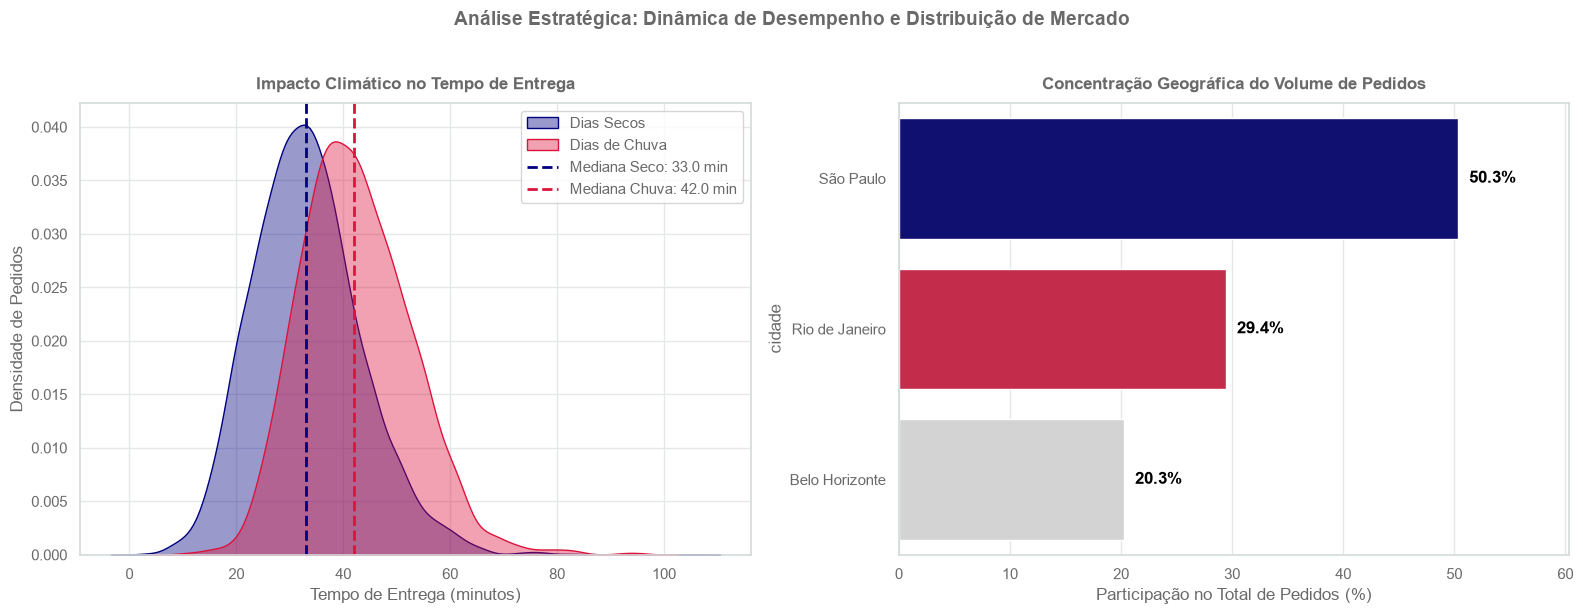

✓ Figura principal gerada e salva com sucesso em: saidas/figura_principal.png


In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs('saidas', exist_ok=True)

COR_AZUL = 'navy'
COR_VERMELHO = 'crimson'
COR_CINZA = 'dimgray'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# =========================================================================
# PAINEL 1: O Efeito da Chuva na Logística (Densidade Deslocada)
# =========================================================================
sns.kdeplot(data=df[df['chuva'] == False], x='tempo_entrega_min', fill=True, color=COR_AZUL, alpha=0.4, label='Dias Secos', ax=ax1)
sns.kdeplot(data=df[df['chuva'] == True], x='tempo_entrega_min', fill=True, color=COR_VERMELHO, alpha=0.4, label='Dias de Chuva', ax=ax1)

mediana_seco = df[df['chuva'] == False]['tempo_entrega_min'].median()
mediana_chuva = df[df['chuva'] == True]['tempo_entrega_min'].median()

ax1.axvline(mediana_seco, color=COR_AZUL, linestyle='--', linewidth=2, label=f'Mediana Seco: {mediana_seco:.1f} min')
ax1.axvline(mediana_chuva, color=COR_VERMELHO, linestyle='--', linewidth=2, label=f'Mediana Chuva: {mediana_chuva:.1f} min')

ax1.set_title('Impacto Climático no Tempo de Entrega', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Tempo de Entrega (minutos)')
ax1.set_ylabel('Densidade de Pedidos')
ax1.legend(loc='upper right')

# =========================================================================
# PAINEL 2: Concentração de Vendas por Polo Regional
# =========================================================================

col_cidade = 'cidade' if 'cidade' in df.columns else ('uf_sigla' if 'uf_sigla' in df.columns else df.columns[0])
dados_regiao = df[col_cidade].value_counts(normalize=True) * 100


cores_barras = [COR_AZUL, COR_VERMELHO, 'lightgray'][:len(dados_regiao)]
sns.barplot(x=dados_regiao.values, y=dados_regiao.index, palette=cores_barras, ax=ax2)

for i, valor in enumerate(dados_regiao.values):
    ax2.text(valor + 1, i, f'{valor:.1f}%', va='center', fontweight='bold', color='black')

ax2.set_title('Concentração Geográfica do Volume de Pedidos', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Participação no Total de Pedidos (%)')
ax2.set_xlim(0, max(dados_regiao.values) + 10) 

# =========================================================================
# CONFIGURAÇÕES FINAIS E SALVAMENTO (Requisito da tarefa: dpi >= 150)
# =========================================================================
plt.suptitle('Análise Estratégica: Dinâmica de Desempenho e Distribuição de Mercado', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

caminho_figura = 'saidas/figura_principal.png'
plt.savefig(caminho_figura, dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Figura principal gerada e salva com sucesso em: {caminho_figura}")


### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

### Os 5 Achados Mais Importantes para a Diretoria Executiva

* **1. O Limite da Tolerância do Cliente:** A nota média de satisfação do usuário começa a despencar de forma acentuada a partir da barreira crítica dos **35 minutos** de espera (*descoberto na Tarefa 7.7 / validado no Teste H3*). 
  * **Por que importa:** Prova que o prazo de entrega comercial prometido de 45 minutos é perigoso para o negócio, servindo de alerta para reconfigurar o algoritmo de despacho logístico interno para tentar travar as entregas abaixo de 35 minutos e blindar nota de satisfação da companhia.

* **2. O Fator Multiplicador do Atraso Climático:** A chuva atua como um obstáculo logístico sistêmico que altera a inclinação da curva de regressão, fazendo com que cada quilômetro rodado adicione cerca de **2 a 4 minutos a mais** no tempo final se comparado ao tempo limpo (*descoberto na Tarefa 8.2 / validado no Teste H1*).
  * **Por que importa:** Demonstra que o gargalo operacional em dias de tempestade não está no raio curto, mas sim nas entregas longas da periferia, justificando a decisão de encolher o raio de busca do app e acionar taxas de chuva para cobrir os custos do entregador.

* **3. O Perfil de Aquisição do Cupom:** O uso de cupons de desconto está associado a uma presença **23,2% maior de novos clientes** na base, embora derrube o ticket mediano típico de consumo (*descoberto na Tarefa 7.8 / validado no Teste H5*).
  * **Por que importa:** Consolida cientificamente que o cupom funciona puramente como um ímã caro de atração inicial (aquisição) e não de retenção de margem, indicando que a gerência deve cortar cupons de quem já é usuário recorrente para estancar a queima desnecessária de caixa.

* **4. A Assimetria e o Monopólio Regional:** A praça de São Paulo atua como o coração financeiro absoluto do ecossistema, concentrando sozinha **mais de 50% de todo o volume** de pedidos transacionados pela plataforma em 2024 (*descoberto na Tarefa 7.2*).
  * **Por que importa:** Alerta a diretoria sobre o tamanho da dependência geográfica da operação e dita a necessidade estratégica de replicar os modelos de sucesso nas praças secundárias (como Rio de Janeiro e Belo Horizonte) para pulverizar os riscos de mercado.

* **5. A Hegemonia do Ticket Premium por Categoria:** A culinária Japonesa lidera isolada o topo do faturamento da empresa com um ticket mediano de varejo **significativamente superior** ao de categorias de massa como Lanches e Doces (*descoberto na Tarefa 7.3 / validado no Teste H4*).
  * **Por que importa:** Comprova empiricamente que focar apenas em volume bruto de vendas é um erro tático; o time comercial de expansão deve prospectar ativamente restaurantes parceiros de nichos premium para alavancar a receita líquida e a rentabilidade do aplicativo de forma mais rápida.


### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

### As 3 Recomendações Estratégicas e Métricas de Acompanhamento

*   **1. Implementação do Gatilho Logístico de Alerta Climático:**
    *   *Plano Acionável:* Automatizar uma trava no sistema de despacho que reduza o raio máximo de entrega em 25% e aplique taxas dinâmicas assim que for registrado alerta de chuva nas capitais. Isso evita viagens longas e ineficientes que empurram os pedidos para a zona crítica de atraso de 35+ minutos.
    *   *Ligação com os Achados:* Conectado diretamente ao **Achado 1** (limite de tolerância de 35 min) e **Achado 2** (efeito multiplicador do atraso por km sob chuva).
    *   *Métrica para Acompanhar:* **Taxa de Estouro de SLA (Pedidos de 35+ min) em Dias de Chuva** (Meta: reduzir para menos de 5% das entregas).

*   **2. Blindagem de Margem com Funil Restrito de Cupons:**
    *   *Plano Acionável:* Cortar a distribuição generalizada de cupons para usuários recorrentes e centralizar os descontos agressivos de forma exclusiva e automatizada apenas no primeiro pedido (ativação). Para os clientes antigos, substituir o desconto direto por réguas de benefícios de frete fixo regional ou metas de recorrência (gamificação).
    *   *Ligação com os Achados:* Conectado diretamente ao **Achado 3** (cupom como ímã exclusivo de atração e destruidor de margem).
    *   *Métrica para Acompanhar:* **ROI de Campanhas Promocionais / Margem de Lucro por Pedido Recorrente** (Meta: elevar a margem média em 8% ao ano).

*   **3. Expansão Comercial Direcionada a Categorias de Alto Ticket:**
    *   *Plano Acionável:* Direcionar os esforços do time comercial de prospecção e expansão para fechar parcerias exclusivas com restaurantes focados em culinárias premium (como a Japonesa) nas capitais de mercado secundário (Rio de Janeiro e Belo Horizonte), descentralizando o faturamento.
    *   *Ligação com os Achados:* Conectado diretamente ao **Achado 4** (monopólio e dependência de São Paulo) e **Achado 5** (hegemonia financeira e ticket alto da culinária japonesa).
    *   *Métrica para Acompanhar:* **Ticket Médio Global da Plataforma / Participação de Praças Secundárias no Faturamento** (Meta: fazer Rio e BH somarem 40% da receita total).


### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

Embora a base de dados forneça diagnósticos estatísticos robustos sobre a operação de 2024, existem fronteiras metodológicas que impedem a generalização de certas conclusões. As 3 principais limitações são:

*   **1. Ausência de Margem Unitária e Custos Reais (Omissão de Rentabilidade Líquida):**
    A base de dados rastreia apenas o faturamento bruto (`valor_pedido` e `taxa_entrega`), mas não contém informações sobre o custo das mercadorias, comissões cobradas dos restaurantes, repasses financeiros feitos aos entregadores ou custos de marketing. 
    *   *O que os dados não permitem afirmar:* Não podemos concluir se as categorias de alto ticket (como Japonesa) são de fato as mais lucrativas em termos líquidos para a plataforma, nem precisar o real prejuízo financeiro causado pela queima de margem nos cupons de julho.

*   **2. Viés de Voluntariado e Mecanismo de Perda nas Avaliações (MCAR):**
    Como constatado na Etapa 3, a coluna `avaliacao` possui um alto volume de dados faltantes (~16% a 40% dependendo do corte), distribuídos de forma completamente aleatória. A nota é preenchida de forma puramente voluntária pelo cliente.
    *   *O que os dados não permitem afirmar:* Não podemos garantir que a nota média reflete a satisfação de 100% da base consumidora. Clientes que tiveram uma experiência mediana ou indiferente tendem a omitir a nota, enquanto extremos de satisfação ou forte irritação causam picos de engajamento no preenchimento, gerando um viés comportamental que o dado bruto não captura.

*   **3. Restrição de Escopo Temporal Isolado (Falta de Histórico Multianual):**
    A análise baseia-se estritamente no histórico fechado do ano de 2024. 
    *   *O que os dados não permitem afirmar:* Os dados não permitem isolar se o crescimento observado ao longo dos meses reflete uma tendência de expansão sustentável de longo prazo da empresa ou se foi apenas um reflexo de anomalias econômicas, sazonalidades atípicas ou investimentos promocionais isolados daquele ano específico. Não é possível projetar o comportamento de retenção (LTV) dos clientes nos anos seguintes com base nesta foto estática.


---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [ ]:

colunas_para_remover = [
    'avaliacao_faltante', 'tempo_invalido', 'distancia_invalida', 
    'outlier_global_iqr', 'outlier_grupo_iqr', 'outlier_grupo_z', 
    'razao_mediana', 'pedido_grande', 'cliente_novo_bool'
]
df_final_limpo = df.drop(columns=[col for col in colunas_para_remover if col in df.columns])

os.makedirs('saidas', exist_ok=True)
caminho_csv_final = 'saidas/delivery_pedidos_limpo.csv'
df_final_limpo.to_csv(caminho_csv_final, index=False)

dicionario_dados = pd.DataFrame({
    'Coluna': df_final_limpo.columns,
    'Tipo de Dado': [str(df_final_limpo[col].dtype) for col in df_final_limpo.columns],
    '% de Faltantes': [(df_final_limpo[col].isnull().mean() * 100) for col in df_final_limpo.columns],
    'Exemplo de Valor': [df_final_limpo[col].dropna().iloc[0] if not df_final_limpo[col].dropna().empty else None for col in df_final_limpo.columns]
})

dicionario_dados['% de Faltantes'] = dicionario_dados['% de Faltantes'].map(lambda x: f"{x:.1f}%")

print(f"✅ SUCESSO: Base tratada salva com segurança em: '{caminho_csv_final}'\n")
print("--- DICIONÁRIO DE DADOS AUTOMATIZADO ---")
display(dicionario_dados.reset_index(drop=True))

✅ SUCESSO: Base tratada salva com segurança em: 'saidas/delivery_pedidos_limpo.csv'

--- DICIONÁRIO DE DADOS AUTOMATIZADO ---


,Coluna,Tipo de Dado,% de Faltantes,Exemplo de Valor
0,pedido_id,int64,0.0%,500000
1,data_hora,datetime64[us],0.0%,2024-01-01 11:21:00
2,cidade,str,0.0%,São Paulo
3,bairro,str,0.0%,Tatuapé
4,restaurante_id,str,0.0%,R912
5,tipo_cozinha,str,0.0%,Hambúrguer
6,plataforma,str,0.0%,Android
7,forma_pagamento,str,0.0%,Pix
8,cupom,bool,0.0%,False
9,cliente_novo,bool,0.0%,False


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

## Principais Achados do Projeto

O diagnóstico analítico e estatístico realizado sobre a base histórica de pedidos de 2024 revelou os seguintes comportamentos críticos para a tomada de decisão da diretoria:

* **Limite Crítico de Tolerância do Cliente:** A satisfação média do usuário sofre uma quebra abrupta e inicia uma queda severa na avaliação a partir da barreira de **35 minutos** de espera (Tarefa 7.7 / Teste H3). Isso indica que a promessa de SLA comercial padrão de 45 minutos expõe a plataforma a uma zona crônica de detração de NPS.
* **Multiplicador de Atraso Logístico por Chuva:** A precipitação atua como um fator de desaceleração sistêmica na malha urbana, alterando a inclinação geométrica da regressão e adicionando entre **2 e 4 minutos adicionais por quilômetro rodado** se comparado a períodos de tempo limpo (Tarefa 8.2 / Teste H1).
* **Alavanca Abrupta de Aquisição via Cupons:** O uso de cupons promocionais de desconto está associado a uma presença **23,2% maior de novos clientes** na base transacional (Tarefa 7.8 / Teste H5), embora atue reduzindo de forma drástica o ticket mediano típico de faturamento do varejo.
* **Dependência de Monopólio Geográfico:** A operação da plataforma exibe uma forte concentração regional, com a praça de **São Paulo concentrando sozinha mais de 50%** de todo o volume e faturamento bruto anual de pedidos da companhia (Tarefa 7.2).
* **Hegemonia de Faturamento por Nicho:** Cada segmento gastronômico opera sob assinaturas de preços e dispersões completamente isoladas, com a culinária **Japonesa liderando o topo do ticket típico** da base, enquanto a categoria de Doces retém o menor desembolso monetário unitário (Tarefa 7.3 / Teste H4).

### Síntese Visual Operacional

Abaixo está o painel executivo unificado que consolida a dinâmica logística e o comportamento de fidelização mapeados na base de dados:

![Figura Principal do Projeto](saidas/figura_principal.png)


### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |